# High Energy Notebook — Proton and Pion (analog of the muon/electron notebook)

This is the proton/pion analog of "High_energy_notebook_electron_muon.ipynb"


After reading the files:

In [1]:
import os
os.chdir('..')

import robi.core as core
import matplotlib.gridspec as gridspec

from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D
from mpl_toolkits.mplot3d import Axes3D #for 3D projection

2026-10-05 18:54:45.332488: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-05 18:54:45.378496: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-10-05 18:54:46.372798: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
input_standalone_proton_s1_csv = 'data/simulations/regression-proton/proton_standalone_N100000_M0_20GeV_reg_balanced_s1_v3.csv'
input_standalone_proton_s2_csv = 'data/simulations/regression-proton/proton_standalone_N100000_M0_20GeV_reg_balanced_s2_v3.csv'

df_standalone_proton_s1 = core.pd.read_csv(input_standalone_proton_s1_csv)
print("Number of hits in Proton Standalone Seed 1: ", len(df_standalone_proton_s1))

df_standalone_proton_s2 = core.pd.read_csv(input_standalone_proton_s2_csv)
print("Number of hits in Proton Standalone Seed 2: ", len(df_standalone_proton_s2))

df_standalone_proton_s1 = core.shifted_z(df_standalone_proton_s1)
print("Range of Coordinate of Z in Proton Standalone Seed 1:", round(df_standalone_proton_s1["z"].min(), 2), round(df_standalone_proton_s1["z"].max(), 2))

df_standalone_proton_s2 = core.shifted_z(df_standalone_proton_s2)
print("Range of Coordinate of Z in Proton Standalone Seed 2:", round(df_standalone_proton_s2["z"].min(), 2), round(df_standalone_proton_s2["z"].max(), 2))

Number of hits in Proton Standalone Seed 1:  54740548
Number of hits in Proton Standalone Seed 2:  54822842
Range of Coordinate of Z in Proton Standalone Seed 1: 13.4 1222.9
Range of Coordinate of Z in Proton Standalone Seed 2: 13.4 1222.9


In [3]:
input_standalone_pion_s1_csv = 'data/simulations/regression-pion/pion_standalone_N100000_M0_20GeV_reg_balanced_s1_v3.csv'
input_standalone_pion_s2_csv = 'data/simulations/regression-pion/pion_standalone_N100000_M0_20GeV_reg_balanced_s2_v3.csv'

df_standalone_pion_s1 = core.pd.read_csv(input_standalone_pion_s1_csv)
print("Number of hits in Pion Standalone Seed 1: ", len(df_standalone_pion_s1))

df_standalone_pion_s2 = core.pd.read_csv(input_standalone_pion_s2_csv)
print("Number of hits in Pion Standalone Seed 2: ", len(df_standalone_pion_s2))

df_standalone_pion_s1 = core.shifted_z(df_standalone_pion_s1)
print("Range of Coordinate of Z in Pion Standalone Seed 1:", round(df_standalone_pion_s1["z"].min(), 2), round(df_standalone_pion_s1["z"].max(), 2))

df_standalone_pion_s2 = core.shifted_z(df_standalone_pion_s2)
print("Range of Coordinate of Z in Pion Standalone Seed 2:", round(df_standalone_pion_s2["z"].min(), 2), round(df_standalone_pion_s2["z"].max(), 2))

Number of hits in Pion Standalone Seed 1:  49110973
Number of hits in Pion Standalone Seed 2:  48965087
Range of Coordinate of Z in Pion Standalone Seed 1: 13.4 1222.9
Range of Coordinate of Z in Pion Standalone Seed 2: 13.4 1222.9


In [4]:
print(f"Memory usage (pion s1): {df_standalone_pion_s1.memory_usage(deep=True).sum() / (1024**3):.2f} GB")
print(f"Memory usage (pion s2): {df_standalone_pion_s2.memory_usage(deep=True).sum() / (1024**3):.2f} GB")
print(f"Memory usage (proton s1): {df_standalone_proton_s1.memory_usage(deep=True).sum() / (1024**3):.2f} GB")
print(f"Memory usage (proton s2): {df_standalone_proton_s2.memory_usage(deep=True).sum() / (1024**3):.2f} GB")

Memory usage (pion s1): 15.24 GB
Memory usage (pion s2): 15.20 GB
Memory usage (proton s1): 16.93 GB
Memory usage (proton s2): 16.96 GB


We print out X, Y, Z: local, filter and print incoming_theta and incoming_phi (between 0.05 and 0.63 radians, for non-perpendicular incidences) and other parameters, generating the first comparative table. We also implemented r_local = sqrt(x_local^2 + y_local^2), radius vector from shower's local centroid to hit position (how wide is the shower transversally)

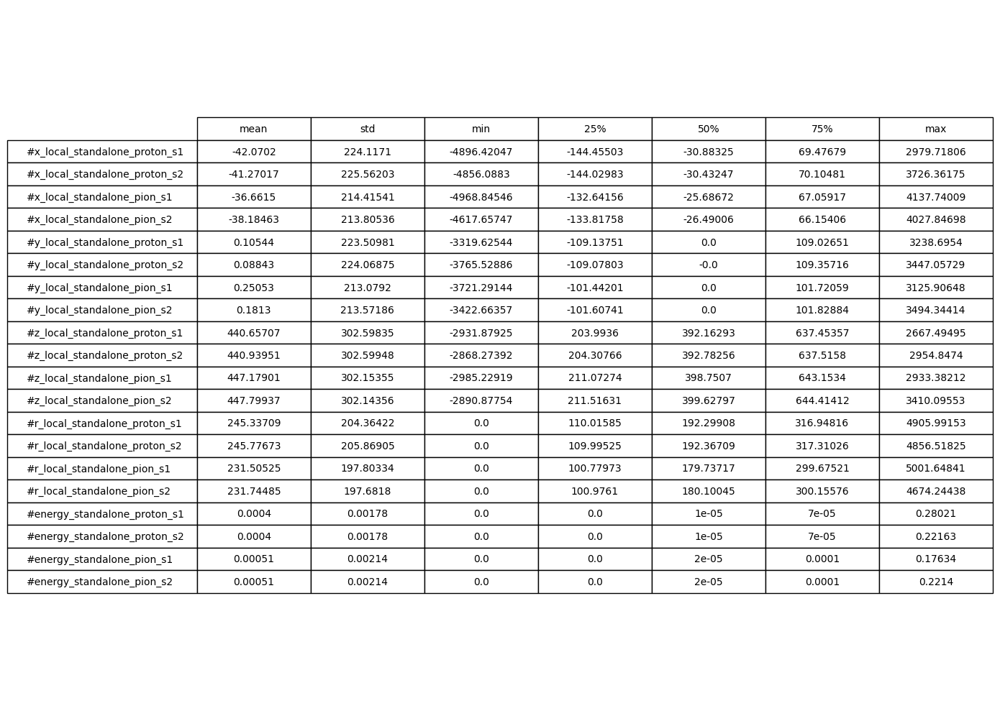

Proton S1: events with theta in [3°, 36°]: 100000
Proton S2: events with theta in [3°, 36°]: 100000
Pion S1: events with theta in [3°, 36°]: 100000
Pion S2: events with theta in [3°, 36°]: 100000


In [5]:
#Figure comparative table

def create_feature_summary(df, mark):
    tmp = df.describe()
    tmp = tmp[1:]
    if 'event_number' in tmp.columns:
        tmp.drop(columns=['event_number'], inplace=True)

    if 'event_id' in tmp.columns:
        tmp.drop(columns=['event_id'], inplace=True)

    new_column_names = {col : "#" + col + mark for col in tmp.columns}
    tmp.rename(columns=new_column_names, inplace=True)
    return tmp

for df_ in [df_standalone_proton_s1, df_standalone_proton_s2,
            df_standalone_pion_s1, df_standalone_pion_s2]:
    df_['r_local'] = core.np.sqrt(df_['x_local']**2 + df_['y_local']**2)

summary_aggr = []
summary_aggr.append(create_feature_summary(df_standalone_proton_s1, "_standalone_proton_s1"))
summary_aggr.append(create_feature_summary(df_standalone_proton_s2, "_standalone_proton_s2"))
summary_aggr.append(create_feature_summary(df_standalone_pion_s1, "_standalone_pion_s1"))
summary_aggr.append(create_feature_summary(df_standalone_pion_s2, "_standalone_pion_s2"))

summary_aggr = core.pd.concat(summary_aggr, axis=1).T

comparative_table = core.pd.concat([
    #dropping x, y, z: NEW modification
    summary_aggr[summary_aggr.index.str.contains("#x_local")],
    summary_aggr[summary_aggr.index.str.contains("#y_local")],
    summary_aggr[summary_aggr.index.str.contains("#z_local")],
    summary_aggr[summary_aggr.index.str.contains("#r_local")],
    summary_aggr[summary_aggr.index.str.contains("#energy")]
])

comparative_table

fig, ax = core.plt.subplots(figsize=(14, 10))
ax.axis('off')

table_data = comparative_table.round(5)

tbl = ax.table(
    cellText=table_data.values,
    rowLabels=table_data.index,
    colLabels=table_data.columns,
    cellLoc='center',
    loc='center'
)

tbl.auto_set_font_size(False)
tbl.set_fontsize(10)
tbl.scale(1, 1.5)

core.plt.tight_layout()
core.plt.savefig(
    'sofiya/images/comparative_table_x_y_z_energy_proton_pion.png',
    dpi=300,
    bbox_inches='tight'
)
core.plt.show()

# incident-angle range, per particle/seed
for name, df_ in [("Proton S1", df_standalone_proton_s1), ("Proton S2", df_standalone_proton_s2),
                   ("Pion S1", df_standalone_pion_s1), ("Pion S2", df_standalone_pion_s2)]:
    n = df_[(df_['incoming_theta'] >= 0.05) & (df_['incoming_theta'] <= 0.63)]['event_number'].nunique()
    print(f"{name}: events with theta in [3°, 36°]: {n}")


Comparative figures and visualizations

1. 2D visualization: Global vs. Local Coordinate Systems

In [6]:
REQUIRED_COLUMNS = {
    'event_number', 'x', 'y', 'z', 'energy',
    'incoming_theta', 'incoming_phi', 'incoming_momentum', 'particle_type',
    'x_local', 'y_local', 'z_local',
}

# ----------------------------------------------------------------------------
# Helper Functions
# ----------------------------------------------------------------------------
def _select_events(df, n_events, top_pool_size, seed):
    """Selects from events with above-average hits from the pool with the largest theta."""
    grouped = df.groupby('event_number')
    hit_counts = grouped.size()
    angles = grouped[['incoming_theta', 'incoming_phi']].first()
    mean_hits = hit_counts.mean()
    print(f"Average number of hits in an event: {mean_hits:.1f}")

    dense = angles[hit_counts > mean_hits]
    pool = (dense.sort_values('incoming_theta', ascending=False)
                 .head(top_pool_size).index.to_numpy())
    if len(pool) == 0:
        return []
    rng = core.np.random.default_rng(seed)
    return rng.choice(pool, size=min(n_events, len(pool)), replace=False).tolist()


def _principal_axis_tilt_deg(xl, yl, zl, w):
    """Angle between the principal axis of the energy-weighted hit cloud and the z' axis (degrees)."""
    pts = core.np.column_stack([xl, yl, zl])
    d = pts - core.np.average(pts, axis=0, weights=w)
    cov = (d * w[:, None]).T @ d / w.sum()
    _, vecs = core.np.linalg.eigh(cov)                  # ascending eigenvalues
    return core.np.degrees(core.np.arccos(core.np.clip(abs(vecs[2, -1]), 0.0, 1.0)))


def _scatter(ax, u, v, e, norm, cmap):
    """Draws sorted by energy, so high-energy hits are on top."""
    order = core.np.argsort(e)
    return ax.scatter(u[order], v[order], c=core.np.clip(e[order], norm.vmin, None),
                      cmap=cmap, norm=norm, s=26, alpha=0.85, linewidths=0, zorder=2)


def _style(ax, xlim, ylim, xlabel, ylabel):
    ax.set(xlim=xlim, ylim=ylim, xlabel=xlabel, ylabel=ylabel)
    ax.set_aspect('equal', adjustable='box')      # tilt is visible at true angle
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.locator_params(nbins=5)
    ax.tick_params(labelsize=9)


def _draw_direction(ax, p, d, L):
    """From point p in direction d: dashed forward, dotted backward line."""
    ax.plot([p[0], p[0] + L * d[0]], [p[1], p[1] + L * d[1]],
            color='black', ls='--', lw=1.8, zorder=3)
    ax.plot([p[0], p[0] - L * d[0]], [p[1], p[1] - L * d[1]],
            color='0.45', ls=':', lw=1.6, zorder=3)


# ----------------------------------------------------------------------------
# Main Function
# ----------------------------------------------------------------------------
def visualize_transformation_check(df, n_events=5, top_pool_size=20, events=None,
                                   seed=None, pad=1.15, min_half=150, cmap='viridis'):
    """
    Comparison of original (x, y, z), translated-only (x-x0, y-y0, z-z0) and
    shower-fixed / rotated (x', y', z') coordinates.

    The "translated" panel shows the intermediate step: the hit cloud shifted
    so that the shower origin sits at (0, 0, 0), but WITHOUT the rotation that
    aligns the shower axis with z'. Comparing it to the original and to the
    fully local (translated + rotated) panels makes the effect of the
    translation and of the rotation separately visible.

    events : specific event_number list (e.g., [105520]); if None, automatic selection.
    seed   : to make automatic selection reproducible.
    pad    : window margin multiplier (1.15 = 15%).
    Returns the list of displayed event_numbers.
    """
    missing = REQUIRED_COLUMNS - set(df.columns)
    if missing:
        raise KeyError(f"Missing columns: {sorted(missing)}")

    selected = list(events) if events is not None else _select_events(
        df, n_events, top_pool_size, seed)
    if not selected:
        print("No matching events found in the database.")
        return []

    sub = df[df['event_number'].isin(selected)]
    groups = {k: g for k, g in sub.groupby('event_number')}
    selected = [ev for ev in selected if ev in groups]
    if not selected:
        print("Specified events not found in the database.")
        return []
    n = len(selected)

    # Common logarithmic color scale for all panels (original, translated, local)
    e_pos = sub.loc[sub['energy'] > 0, 'energy'].to_numpy()
    norm = LogNorm(vmin=core.np.percentile(e_pos, 1), vmax=e_pos.max())

    # --- Figure Layout (3 groups of 3 columns = 9 columns total) ----------
    fig = core.plt.figure(figsize=(38, 4.2 * n + 1))
    kw = dict(top=0.92, bottom=0.07, wspace=0.30, hspace=0.25)
    gs_o = gridspec.GridSpec(n, 3, left=0.045, right=0.310, **kw)   # original
    gs_t = gridspec.GridSpec(n, 3, left=0.370, right=0.635, **kw)   # translated
    gs_l = gridspec.GridSpec(n, 3, left=0.695, right=0.960, **kw)   # local (rotated)

    marker = dict(marker='X', color='red', markeredgecolor='black',
                  markersize=12, linestyle='none', zorder=5)

    def col_title(ax, i, text):
        if i == 0:
            ax.set_title(text, fontweight='bold', fontsize=12)

    for i, event_id in enumerate(selected):
        evt = groups[event_id]
        x, y, z, xl, yl, zl, e = (evt[c].to_numpy(dtype=float) for c in
                                  ('x', 'y', 'z', 'x_local', 'y_local', 'z_local', 'energy'))
        theta = float(evt['incoming_theta'].iloc[0])
        phi = float(evt['incoming_phi'].iloc[0])
        st, ct, sp, cp = core.np.sin(theta), core.np.cos(theta), core.np.sin(phi), core.np.cos(phi)
        nvec = core.np.array([st * cp, st * sp, ct])       # shower propagation direction

        # Origin: energy-weighted center of mass of the first layer
        z0 = z.min()
        m = z == z0
        x0 = core.np.average(x[m], weights=e[m])
        y0 = core.np.average(y[m], weights=e[m])

        # Translated-only coordinates: shift origin to (0,0,0), no rotation
        xt, yt, zt = x - x0, y - y0, z - z0

        tilt = _principal_axis_tilt_deg(xl, yl, zl, e)

        # --- Event-specific window: all panels same size, equal aspect ---
        half = 0.5 * max(core.np.ptp(a) for a in (x, y, z, xl, yl, zl))
        half = max(half, core.np.abs(xl).max(), core.np.abs(yl).max())
        half = max(half * pad, min_half)
        L = 100 * half                                 # "infinite" long line, clipped by window

        mid = lambda a: 0.5 * (a.max() + a.min())
        win = lambda c: (c - half, c + half)
        xlim, ylim, zlim = win(mid(x)), win(mid(y)), win(mid(z))
        xtlim, ytlim, ztlim = win(mid(xt)), win(mid(yt)), win(mid(zt))
        lim0, zlim_l = win(0.0), win(mid(zl))

        momentum = float(evt['incoming_momentum'].iloc[0])
        primary_hits = evt[evt['is_secondary'] == 0]
        if len(primary_hits):
             ptype = str(primary_hits['particle_type'].iloc[0])
        else:
            ptype = "primary hit missing"
        row_label = (f"Event {event_id}\nHits: {len(evt)}\n"
                     f"{ptype}, p = {momentum:.2f} GeV\n"
                     f"\u03b8 = {core.np.degrees(theta):.1f}\u00b0 ({theta:.3f})\n"
                     f"\u03c6 = {core.np.degrees(phi):.1f}\u00b0 ({phi:.3f})\n"
                     f"origin: ({x0:.0f}, {y0:.0f}, {z0:.0f})")

        # ================= ORIGINAL =================
        # 1. X - Y
        ax = fig.add_subplot(gs_o[i, 0])
        _scatter(ax, x, y, e, norm, cmap)
        _draw_direction(ax, (x0, y0), (nvec[0], nvec[1]), L)
        ax.plot(x0, y0, **marker)
        _style(ax, xlim, ylim, 'X', 'Y')
        ax.set_ylabel(row_label + '\n\nY', fontweight='bold', fontsize=10)
        col_title(ax, i, 'X \u2013 Y projection')

        # 2. X - Z
        ax = fig.add_subplot(gs_o[i, 1])
        _scatter(ax, x, z, e, norm, cmap)
        ax.axhline(z0, color='0.5', ls='-.', lw=1.2, zorder=1)          # plane of 1st layer
        _draw_direction(ax, (x0, z0), (nvec[0], nvec[2]), L)
        ax.plot(x0, z0, **marker)
        _style(ax, xlim, zlim, 'X', 'Z')
        col_title(ax, i, 'X \u2013 Z projection')

        # 3. Y - Z
        ax = fig.add_subplot(gs_o[i, 2])
        _scatter(ax, y, z, e, norm, cmap)
        ax.axhline(z0, color='0.5', ls='-.', lw=1.2, zorder=1)
        _draw_direction(ax, (y0, z0), (nvec[1], nvec[2]), L)
        ax.plot(y0, z0, **marker)
        _style(ax, ylim, zlim, 'Y', 'Z')
        col_title(ax, i, 'Y \u2013 Z projection')

        # ================= TRANSLATED (no rotation) =================
        # 4. Xt - Yt
        ax = fig.add_subplot(gs_t[i, 0])
        _scatter(ax, xt, yt, e, norm, cmap)
        _draw_direction(ax, (0, 0), (nvec[0], nvec[1]), L)
        ax.plot(0, 0, **marker)
        _style(ax, xtlim, ytlim, "X-x\u2080", "Y-y\u2080")
        col_title(ax, i, 'Translated: X \u2013 Y projection')

        # 5. Xt - Zt
        ax = fig.add_subplot(gs_t[i, 1])
        _scatter(ax, xt, zt, e, norm, cmap)
        ax.axhline(0.0, color='0.5', ls='-.', lw=1.2, zorder=1)         # plane of 1st layer (z=0 now)
        _draw_direction(ax, (0, 0), (nvec[0], nvec[2]), L)
        ax.plot(0, 0, **marker)
        _style(ax, xtlim, ztlim, "X-x\u2080", "Z-z\u2080")
        col_title(ax, i, 'Translated: X \u2013 Z projection')

        # 6. Yt - Zt
        ax = fig.add_subplot(gs_t[i, 2])
        _scatter(ax, yt, zt, e, norm, cmap)
        ax.axhline(0.0, color='0.5', ls='-.', lw=1.2, zorder=1)
        _draw_direction(ax, (0, 0), (nvec[1], nvec[2]), L)
        ax.plot(0, 0, **marker)
        _style(ax, ytlim, ztlim, "Y-y\u2080", "Z-z\u2080")
        col_title(ax, i, 'Translated: Y \u2013 Z projection')

        # ================= LOCAL (translated + rotated) =================
        # 7. X' - Y'   (shower axis here is a single point: the origin)
        ax = fig.add_subplot(gs_l[i, 0])
        _scatter(ax, xl, yl, e, norm, cmap)
        ax.plot(0, 0, **marker)
        _style(ax, lim0, lim0, "X'", "Y'")
        ax.text(0.97, 0.03, f"principal axis\u2013z' angle: {tilt:.1f}\u00b0", transform=ax.transAxes,
                ha='right', va='bottom', fontsize=9,
                bbox=dict(boxstyle='round', fc='white', ec='0.7', alpha=0.85))
        col_title(ax, i, "X' \u2013 Y' projection")

        # 8. X' - Z'   (plane of 1st layer here is the line z' = tan\u03b8 \u00b7 x')
        ax = fig.add_subplot(gs_l[i, 1])
        _scatter(ax, xl, zl, e, norm, cmap)
        xs = core.np.array([-L, L])
        ax.plot(xs, core.np.tan(theta) * xs, color='0.5', ls='-.', lw=1.2, zorder=1)
        _draw_direction(ax, (0, 0), (0, 1), L)                          # z' axis
        ax.plot(0, 0, **marker)
        _style(ax, lim0, zlim_l, "X'", "Z'")
        col_title(ax, i, "X' \u2013 Z' projection")

        # 9. Y' - Z'
        ax = fig.add_subplot(gs_l[i, 2])
        _scatter(ax, yl, zl, e, norm, cmap)
        _draw_direction(ax, (0, 0), (0, 1), L)
        ax.plot(0, 0, **marker)
        _style(ax, lim0, zlim_l, "Y'", "Z'")
        col_title(ax, i, "Y' \u2013 Z' projection")

    # --- Group Headers, Separators, Legend, Colorbar -----------------------
    fig.text(0.1775, 0.965, 'ORIGINAL \u2013 detector coordinates (x, y, z)',
             ha='center', fontsize=16, fontweight='bold')
    fig.text(0.5025, 0.965, 'TRANSLATED ONLY \u2013 origin shifted, not rotated (x-x\u2080, y-y\u2080, z-z\u2080)',
             ha='center', fontsize=16, fontweight='bold')
    fig.text(0.8275, 0.965, "LOCAL \u2013 translated + rotated (x', y', z')",
             ha='center', fontsize=16, fontweight='bold')

    for xline in (0.340, 0.665):
        fig.add_artist(Line2D([xline, xline], [0.02, 0.98], transform=fig.transFigure,
                              color='black', linewidth=4, zorder=10))

    handles = [
        Line2D([], [], color='black', ls='--', lw=1.8, label='Incident direction (forward)'),
        Line2D([], [], color='0.45', ls=':', lw=1.6, label='Extrapolated backward'),
        Line2D([], [], color='0.5', ls='-.', lw=1.2, label='1st layer plane (z = z\u2080)'),
        Line2D([], [], marker='X', color='red', markeredgecolor='black', ls='none',
               markersize=11, label='Shower origin (1st layer center of mass)'),
    ]
    fig.legend(handles=handles, loc='lower center', ncol=4, fontsize=12, frameon=False)

    sm = core.plt.cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    cax = fig.add_axes([0.978, 0.30, 0.006, 0.40])
    fig.colorbar(sm, cax=cax, label='Energy (log scale)')

    core.plt.show()
    return selected


=== Proton S1 ===
Average number of hits in an event: 547.4


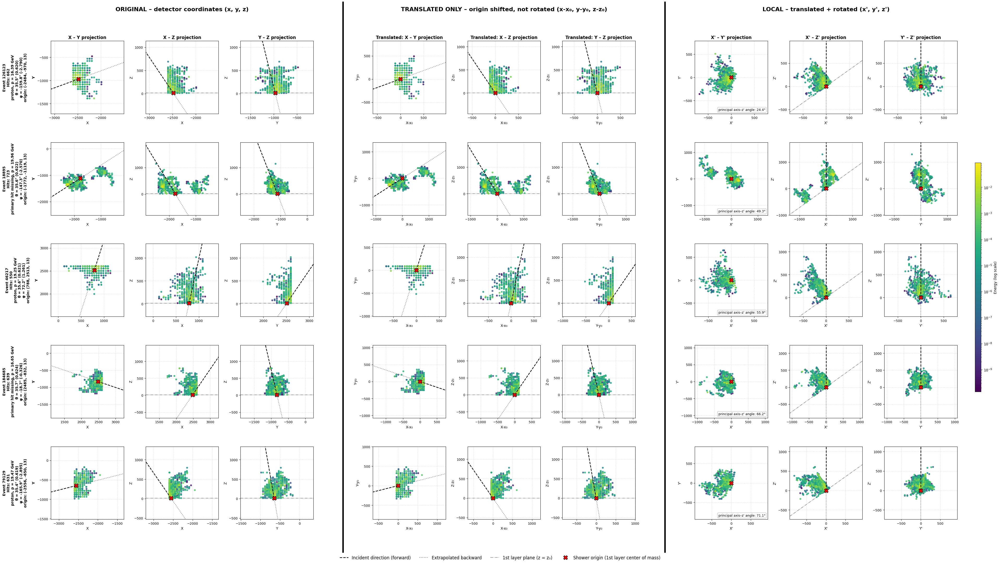

In [7]:
print("=== Proton S1 ===")
_ = visualize_transformation_check(df_standalone_proton_s1, n_events=5, seed=42)

=== Pion S1 ===


Average number of hits in an event: 491.1


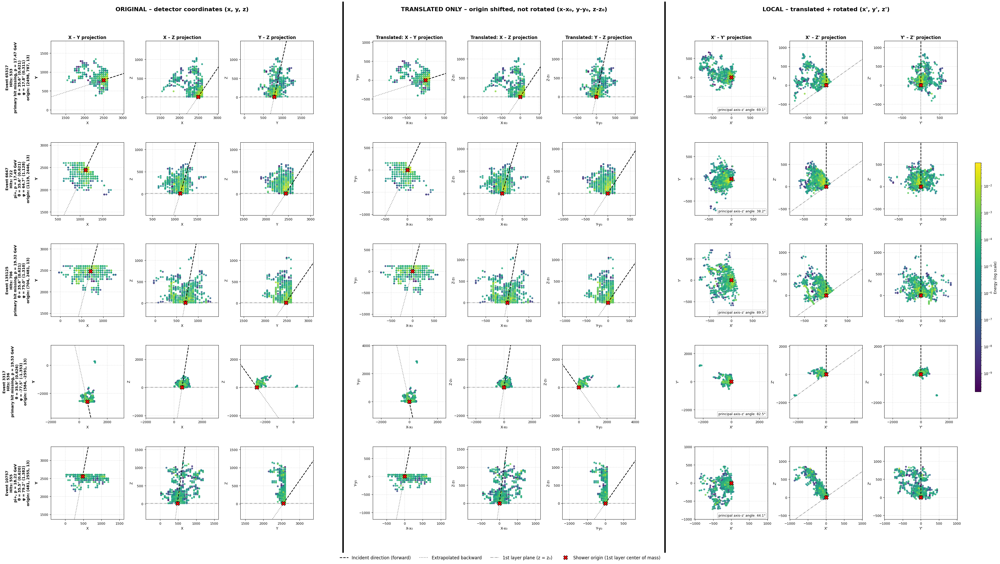

In [8]:
print("=== Pion S1 ===")
_ = visualize_transformation_check(df_standalone_pion_s1, n_events=5, seed=42)

2. 2D visualization: Comparison of local vs. global cross-sections of showers during decreasing energy density; average radial energy distribution visualization

In [9]:
def visualize_superimposed_vs_global(df, max_shower_radius=500, max_shower_length=1500):
    """
    Three-row comparison:
      Row 1 - GLOBAL (original, unbounded range): detector coordinates as recorded
      Row 2 - TRANSLATED ONLY (fixed range): origin shifted to (0,0,0), not rotated
      Row 3 - SUPERIMPOSED / LOCAL (same fixed range as row 2): shifted AND rotated

    Rows 2 and 3 share the same axis range on purpose, so comparing them isolates
    the effect of the rotation alone, separate from the effect of the translation
    (visible by comparing row 1 to row 2).
    """
    fig, axes = core.plt.subplots(nrows=3, ncols=3, figsize=(18, 15))
    bins = 100
    cmap = 'plasma'

    # ==================== ROW 1: GLOBAL (ORIGINAL) ====================
    ax = axes[0, 0]
    h1 = ax.hist2d(df['x'], df['y'], bins=bins, weights=df['energy'], cmap=cmap, cmin=1)
    ax.set_aspect('equal')
    ax.set_title("GLOBAL (ORIGINAL)\nX - Y", fontweight='bold')
    ax.set_xlabel("X (mm)"); ax.set_ylabel("Y (mm)")
    fig.colorbar(h1[3], ax=ax, label='Deposited Energy')

    ax = axes[0, 1]
    h2 = ax.hist2d(df['z'], df['x'], bins=bins, weights=df['energy'], cmap=cmap, cmin=1)
    ax.set_title("GLOBAL (ORIGINAL)\nZ - X", fontweight='bold')
    ax.set_xlabel("Z (mm)"); ax.set_ylabel("X (mm)")
    fig.colorbar(h2[3], ax=ax, label='Deposited Energy')

    ax = axes[0, 2]
    h3 = ax.hist2d(df['z'], df['y'], bins=bins, weights=df['energy'], cmap=cmap, cmin=1)
    ax.set_title("GLOBAL (ORIGINAL)\nZ - Y", fontweight='bold')
    ax.set_xlabel("Z (mm)"); ax.set_ylabel("Y (mm)")
    fig.colorbar(h3[3], ax=ax, label='Deposited Energy')

    # ==================== ROW 2: TRANSLATED ONLY ====================
    ax = axes[1, 0]
    h4 = ax.hist2d(df['x_trans'], df['y_trans'], bins=bins, weights=df['energy'],
                   range=[[-max_shower_radius, max_shower_radius], [-max_shower_radius, max_shower_radius]],
                   cmap=cmap, cmin=1)
    ax.set_aspect('equal')
    ax.set_title("TRANSLATED ONLY\nX-x\u2080 - Y-y\u2080", fontweight='bold')
    ax.set_xlabel("X-x\u2080 (mm)"); ax.set_ylabel("Y-y\u2080 (mm)")
    fig.colorbar(h4[3], ax=ax, label='Deposited Energy')

    ax = axes[1, 1]
    h5 = ax.hist2d(df['z_trans'], df['x_trans'], bins=bins, weights=df['energy'],
                   range=[[-100, max_shower_length], [-max_shower_radius, max_shower_radius]],
                   cmap=cmap, cmin=1)
    ax.set_title("TRANSLATED ONLY\nZ-z\u2080 - X-x\u2080", fontweight='bold')
    ax.set_xlabel("Z-z\u2080 (Depth mm)"); ax.set_ylabel("X-x\u2080 (mm)")
    fig.colorbar(h5[3], ax=ax, label='Deposited Energy')

    ax = axes[1, 2]
    h6 = ax.hist2d(df['z_trans'], df['y_trans'], bins=bins, weights=df['energy'],
                   range=[[-100, max_shower_length], [-max_shower_radius, max_shower_radius]],
                   cmap=cmap, cmin=1)
    ax.set_title("TRANSLATED ONLY\nZ-z\u2080 - Y-y\u2080", fontweight='bold')
    ax.set_xlabel("Z-z\u2080 (Depth mm)"); ax.set_ylabel("Y-y\u2080 (mm)")
    fig.colorbar(h6[3], ax=ax, label='Deposited Energy')

    # ==================== ROW 3: SUPERIMPOSED / LOCAL ====================
    ax = axes[2, 0]
    h7 = ax.hist2d(df['x_local'], df['y_local'], bins=bins, weights=df['energy'],
                   range=[[-max_shower_radius, max_shower_radius], [-max_shower_radius, max_shower_radius]],
                   cmap=cmap, cmin=1)
    ax.set_aspect('equal')
    ax.set_title("SUPERIMPOSED (LOCAL)\nX' - Y'", fontweight='bold')
    ax.set_xlabel("X' (mm)"); ax.set_ylabel("Y' (mm)")
    fig.colorbar(h7[3], ax=ax, label='Deposited Energy')

    ax = axes[2, 1]
    h8 = ax.hist2d(df['z_local'], df['x_local'], bins=bins, weights=df['energy'],
                   range=[[-100, max_shower_length], [-max_shower_radius, max_shower_radius]],
                   cmap=cmap, cmin=1)
    ax.set_title("SUPERIMPOSED (LOCAL)\nZ' - X'", fontweight='bold')
    ax.set_xlabel("Z' (Depth mm)"); ax.set_ylabel("X' (mm)")
    fig.colorbar(h8[3], ax=ax, label='Deposited Energy')

    ax = axes[2, 2]
    h9 = ax.hist2d(df['z_local'], df['y_local'], bins=bins, weights=df['energy'],
                   range=[[-100, max_shower_length], [-max_shower_radius, max_shower_radius]],
                   cmap=cmap, cmin=1)
    ax.set_title("SUPERIMPOSED (LOCAL)\nZ' - Y'", fontweight='bold')
    ax.set_xlabel("Z' (Depth mm)"); ax.set_ylabel("Y' (mm)")
    fig.colorbar(h9[3], ax=ax, label='Deposited Energy')

    core.plt.tight_layout()
    core.plt.show()

=== Proton (S1) — hadronic shower ===


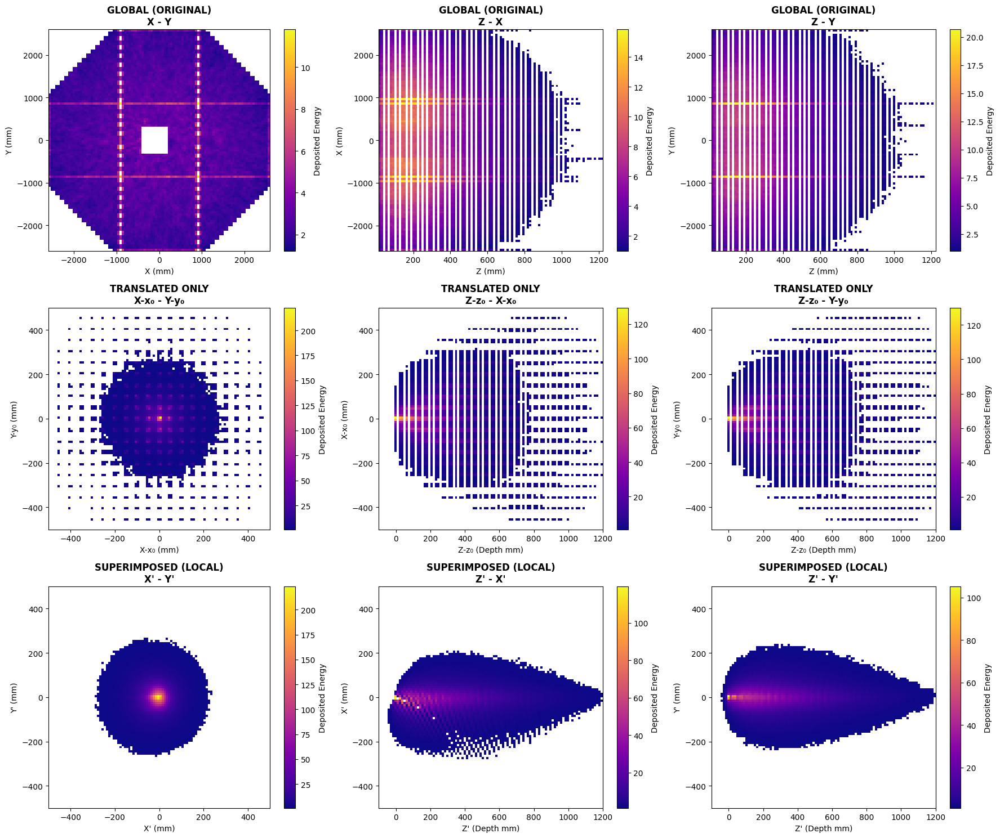

In [10]:
print("=== Proton (S1) — hadronic shower ===")
visualize_superimposed_vs_global(df_standalone_proton_s1, max_shower_radius=500, max_shower_length=1200)

=== Pion (S1) — hadronic shower ===


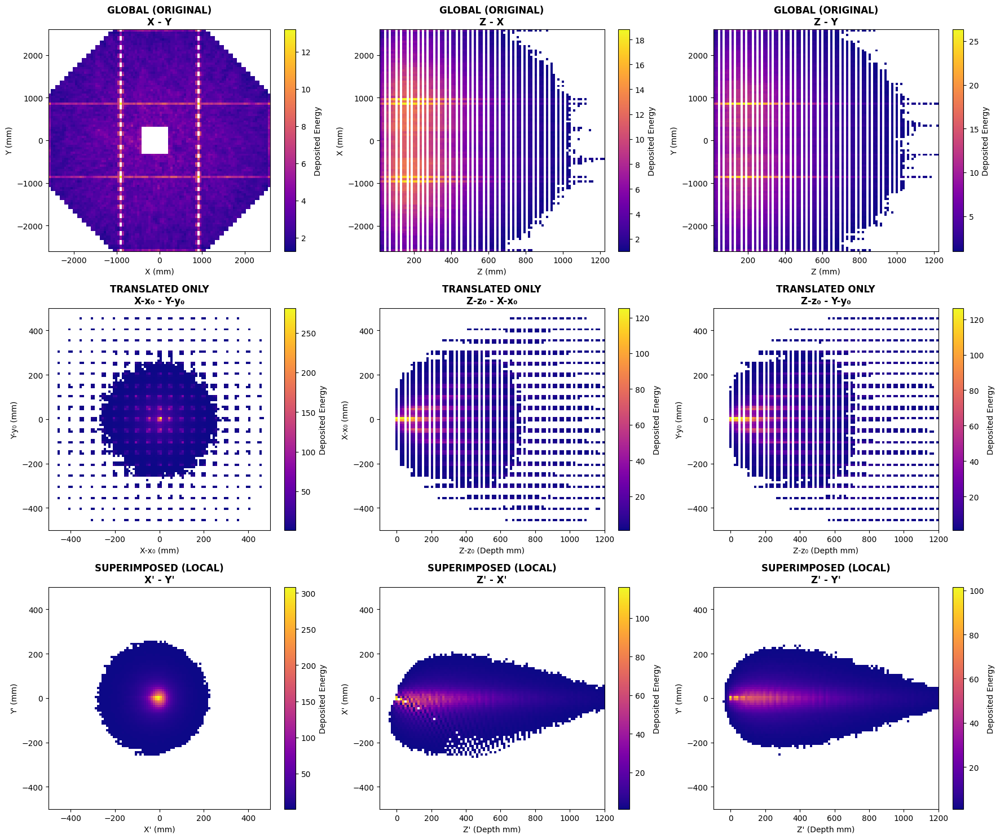

In [11]:
print("=== Pion (S1) — hadronic shower ===")
visualize_superimposed_vs_global(df_standalone_pion_s1, max_shower_radius=500, max_shower_length=1200)

3. 2D visualization: spatial distribution of particles as a function of energy: local

📊 Linear (Energy Bins):   0%|          | 0/7 [00:00<?, ?it/s]

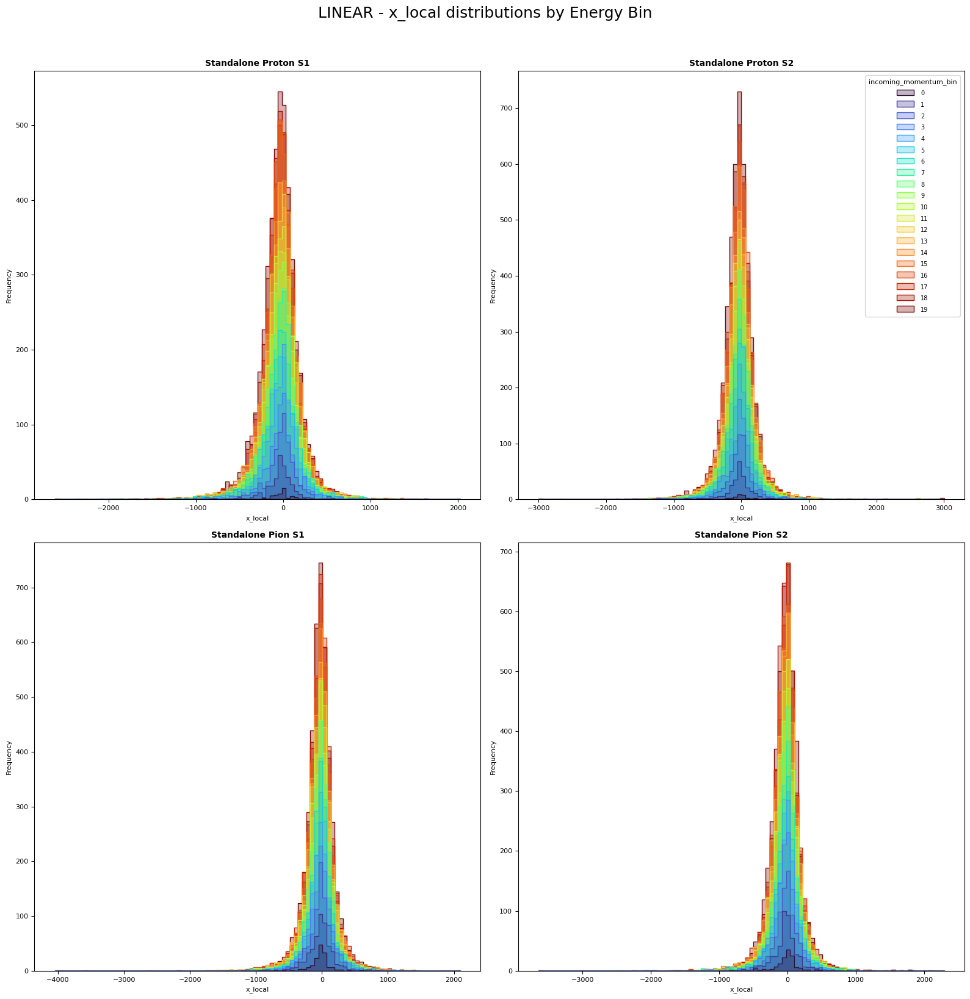

📊 Linear (Energy Bins):  14%|█▍        | 1/7 [00:09<00:58,  9.77s/it]

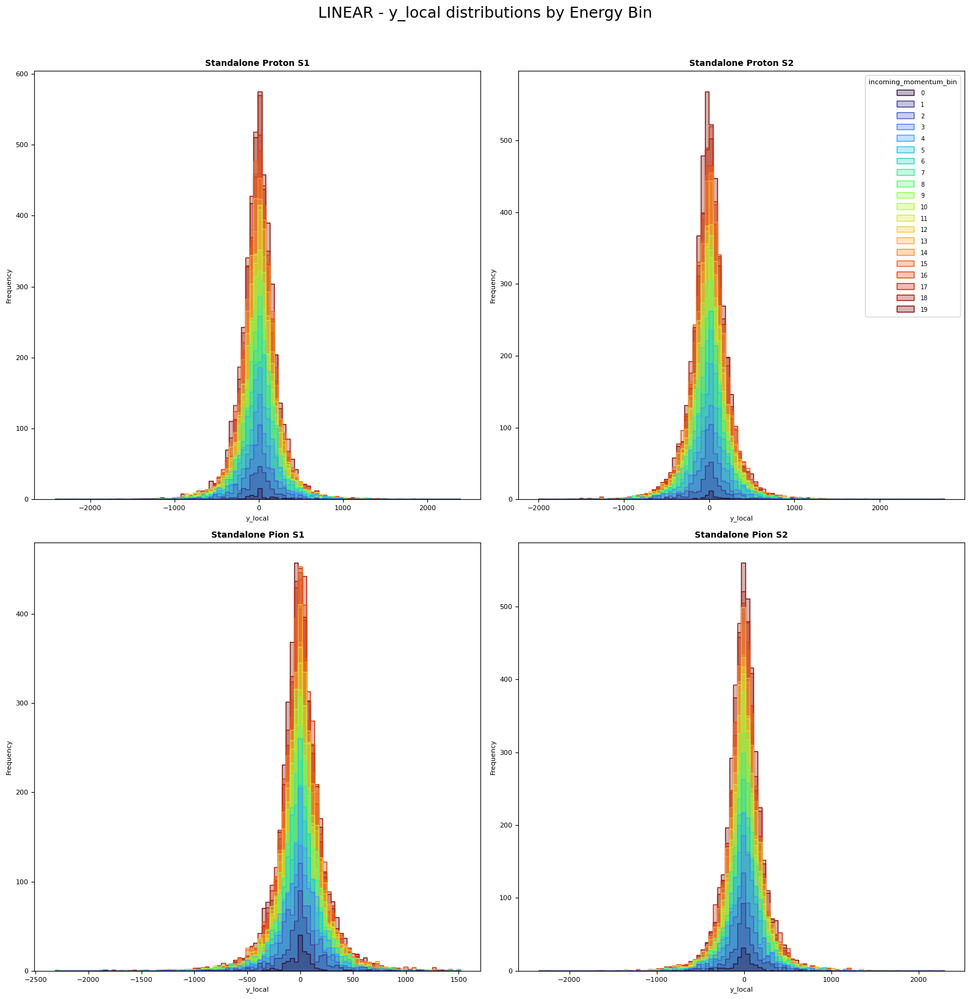

📊 Linear (Energy Bins):  29%|██▊       | 2/7 [00:19<00:48,  9.71s/it]

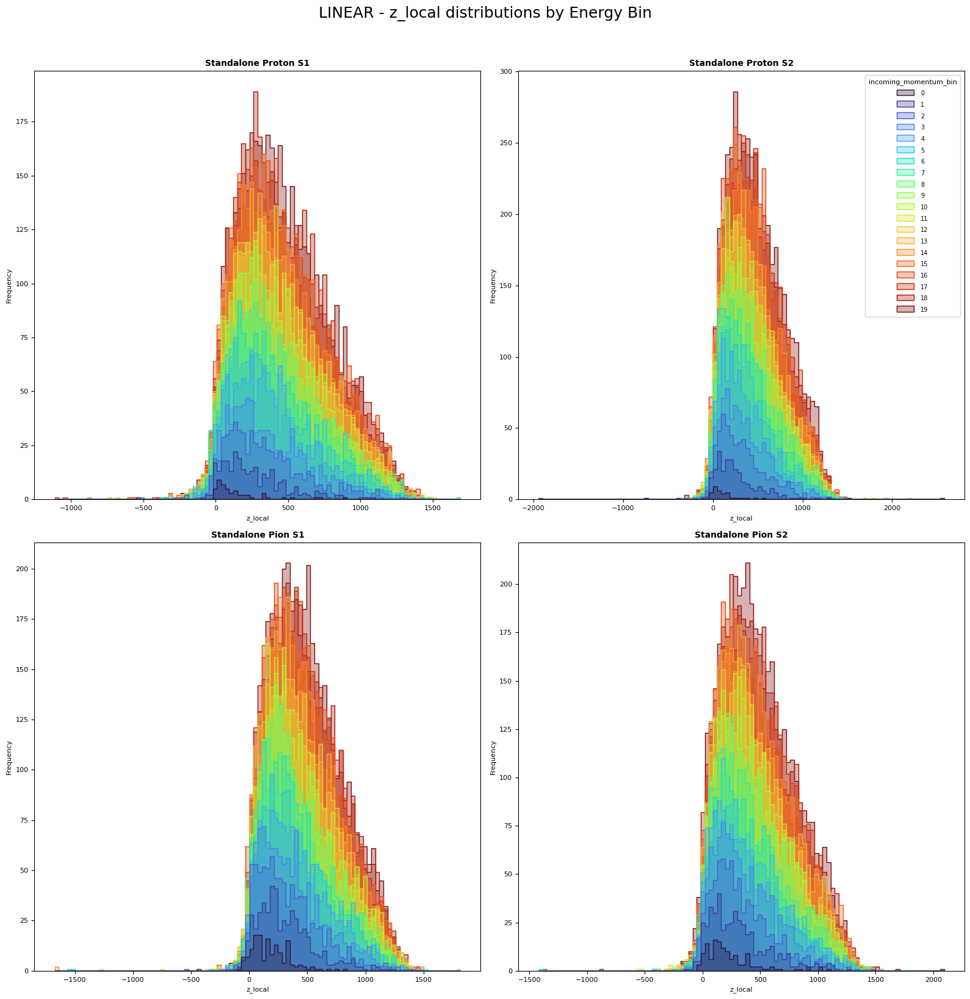

📊 Linear (Energy Bins):  43%|████▎     | 3/7 [00:29<00:38,  9.65s/it]

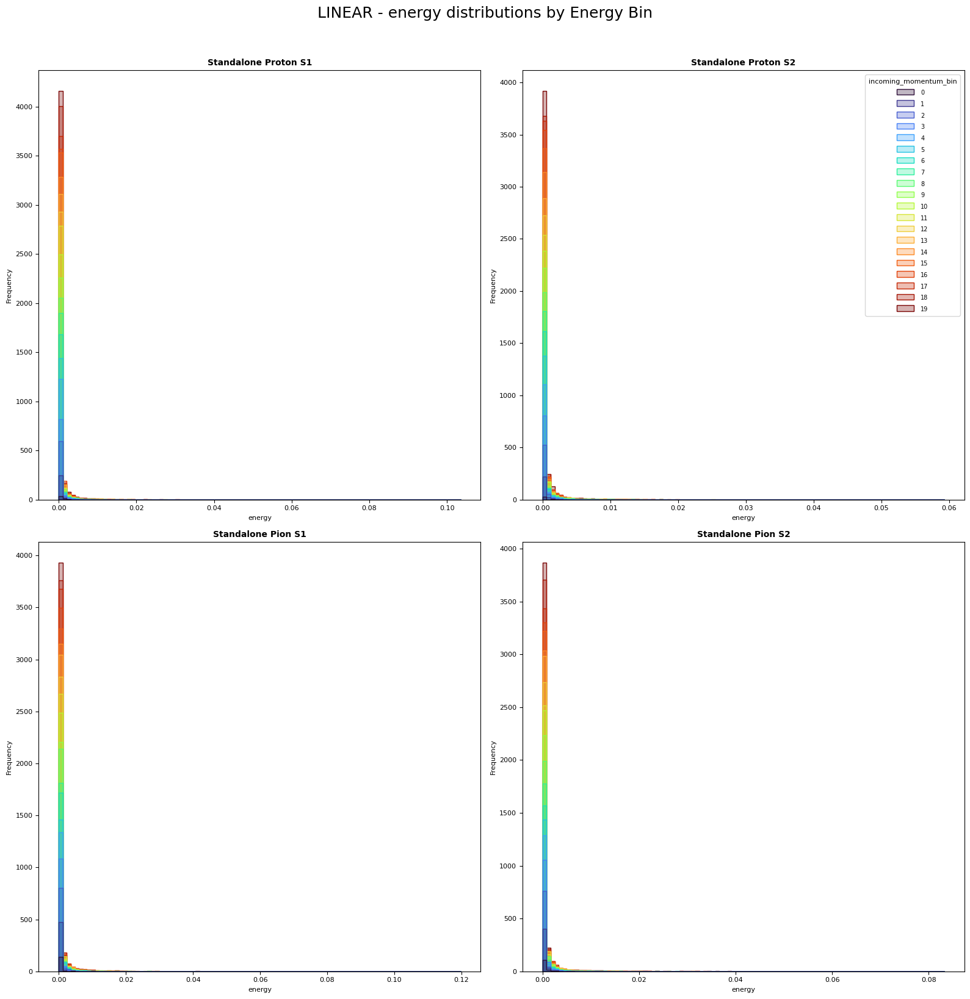

📊 Linear (Energy Bins):  57%|█████▋    | 4/7 [00:38<00:28,  9.61s/it]

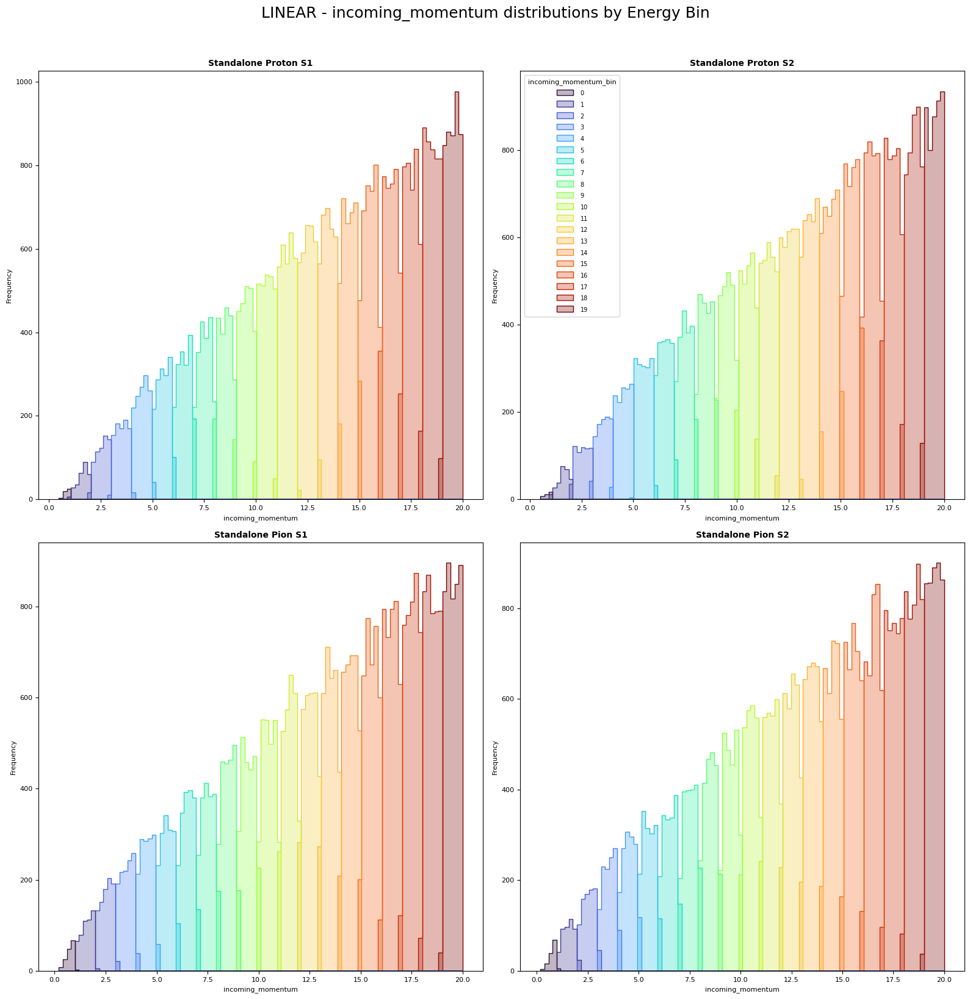

📊 Linear (Energy Bins):  71%|███████▏  | 5/7 [00:48<00:19,  9.62s/it]

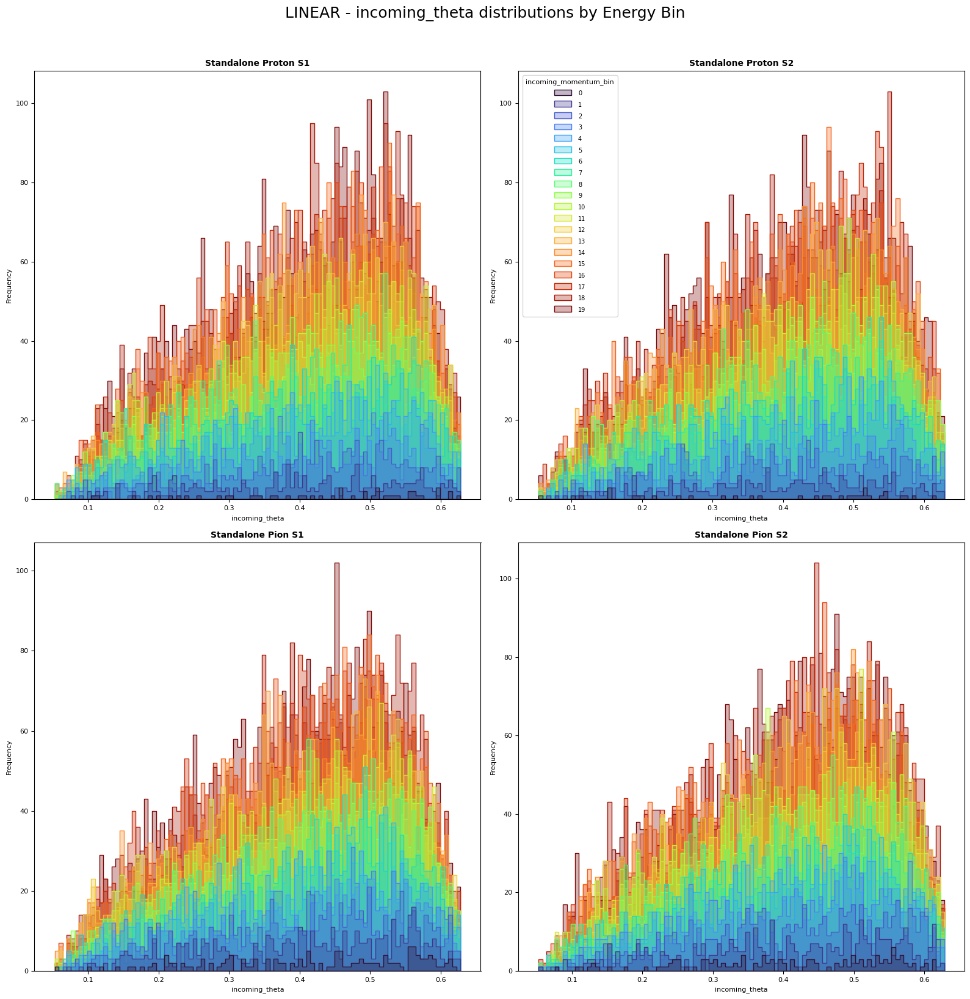

📊 Linear (Energy Bins):  86%|████████▌ | 6/7 [00:58<00:09,  9.73s/it]

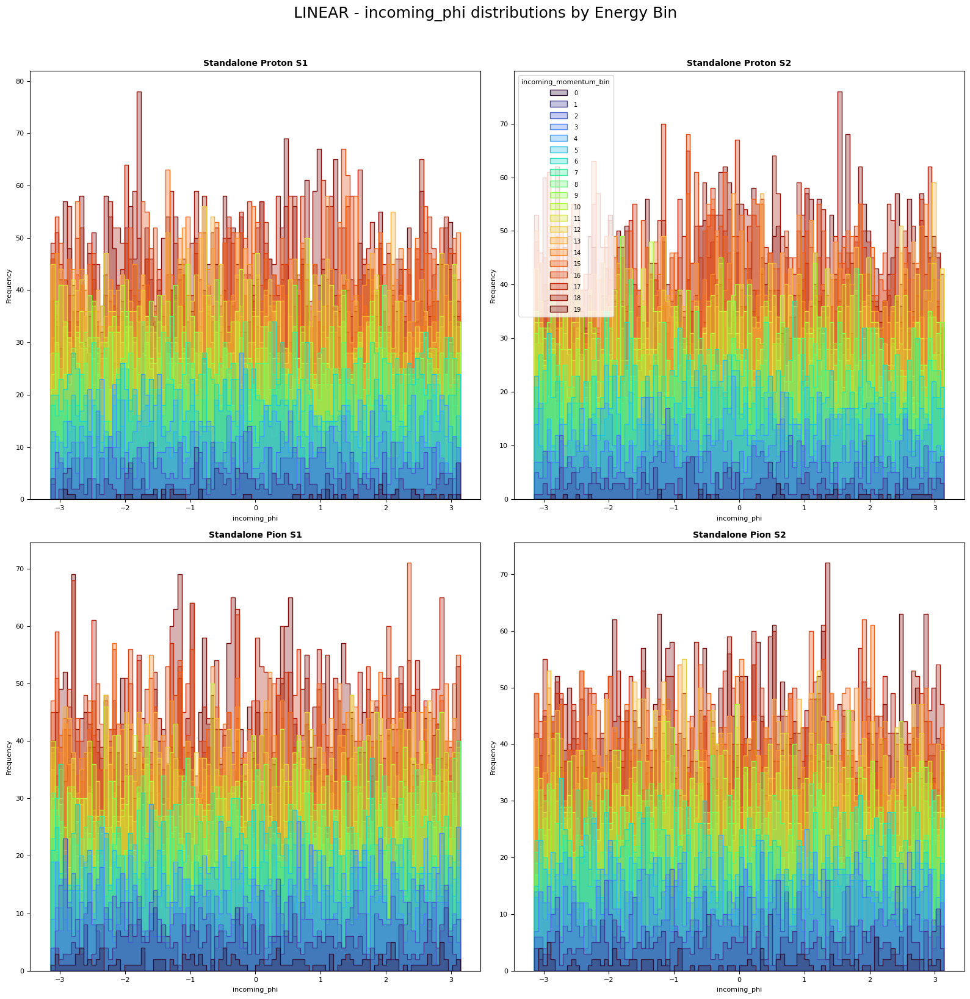

📊 Linear (Energy Bins): 100%|██████████| 7/7 [01:07<00:00,  9.67s/it]


In [12]:
#linear distribution

dataframes_local = {
    'Standalone Proton S1': df_standalone_proton_s1,
    'Standalone Proton S2': df_standalone_proton_s2,
    'Standalone Pion S1': df_standalone_pion_s1,
    'Standalone Pion S2': df_standalone_pion_s2,
}

all_names = list(dataframes_local.keys())

columns_to_plot = ['x_local', 'y_local', 'z_local', 'energy', 'incoming_momentum', 'incoming_theta', 'incoming_phi']

for col in core.tqdm(columns_to_plot, desc="📊 Linear (Energy Bins)"):
    fig, axes = core.plt.subplots(2, 2, figsize=(16, 16))
    axes_flat = axes.flatten()

    for i, name in enumerate(all_names):
        ax = axes_flat[i]
        df = dataframes_local[name]

        # Oszlopok kiválasztása és tisztitása
        cols_needed = [col, 'incoming_momentum_bin']
        data = df[cols_needed].dropna()

        # Mintavételezés (megtartva az energia bin oszlopot)
        sample = data.sample(min(len(data), 50000), random_state=42)

        # HUE alapú plotolás
        core.sns.histplot(
            data=sample,
            x=col,
            hue='incoming_momentum_bin',
            element="step",
            palette="turbo",  # Színatmenetes skála a 20 binhez
            ax=ax,
            bins=100,
            alpha=0.3,
            legend=(i == 1) # Csak a második (jobb felső) ábrán maradjon jelmagyarázat a helytakarékosság miatt
        )

        ax.set_title(f'{name}', fontsize=10, fontweight='bold')
        ax.tick_params(axis='both', labelsize=8)
        ax.set_xlabel(col, fontsize=8)
        ax.set_ylabel('Frequency', fontsize=8)

        # Ha van legenda, vegyük kisebbre
        if ax.get_legend():
            core.plt.setp(ax.get_legend().get_texts(), fontsize='7')
            core.plt.setp(ax.get_legend().get_title(), fontsize='8')

    fig.suptitle(f'LINEAR - {col} distributions by Energy Bin', fontsize=18, y=1.02)
    core.plt.tight_layout()
    core.plt.show()


🚀 Logarithmic (Energy Bins):   0%|          | 0/7 [00:00<?, ?it/s]

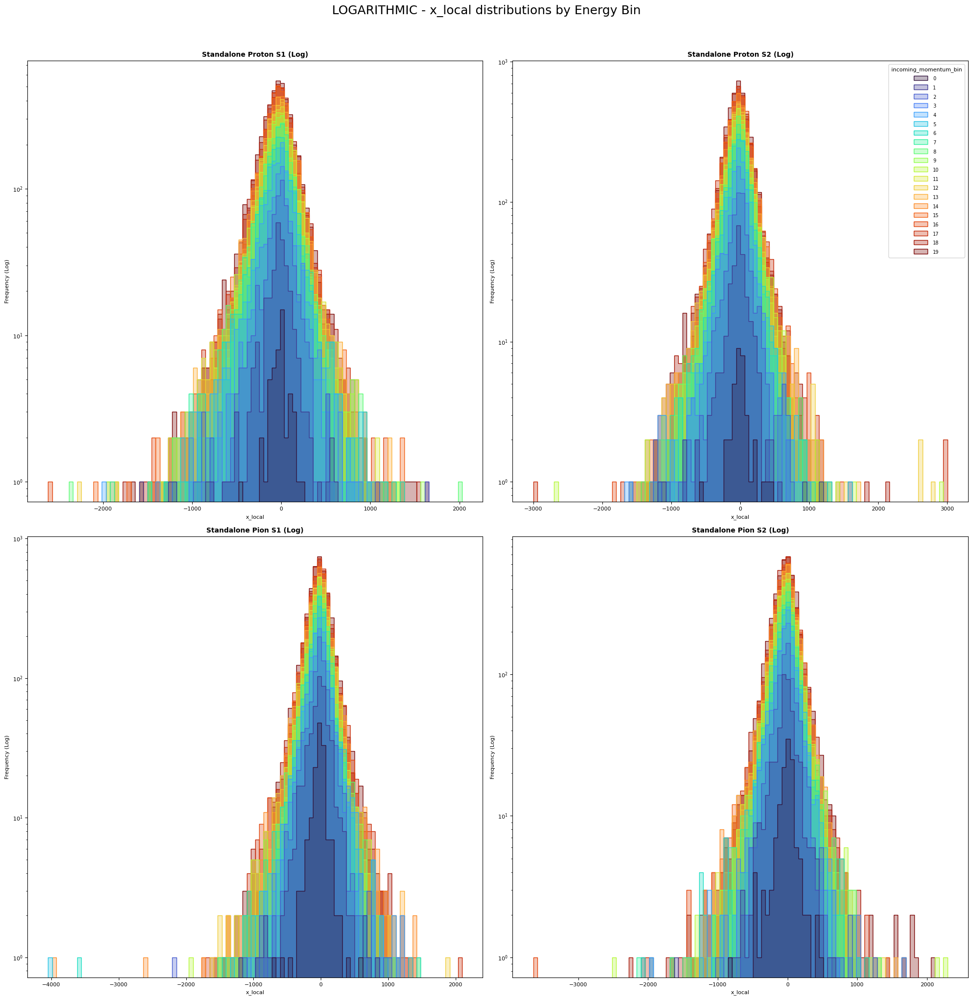

🚀 Logarithmic (Energy Bins):  14%|█▍        | 1/7 [00:10<01:01, 10.33s/it]

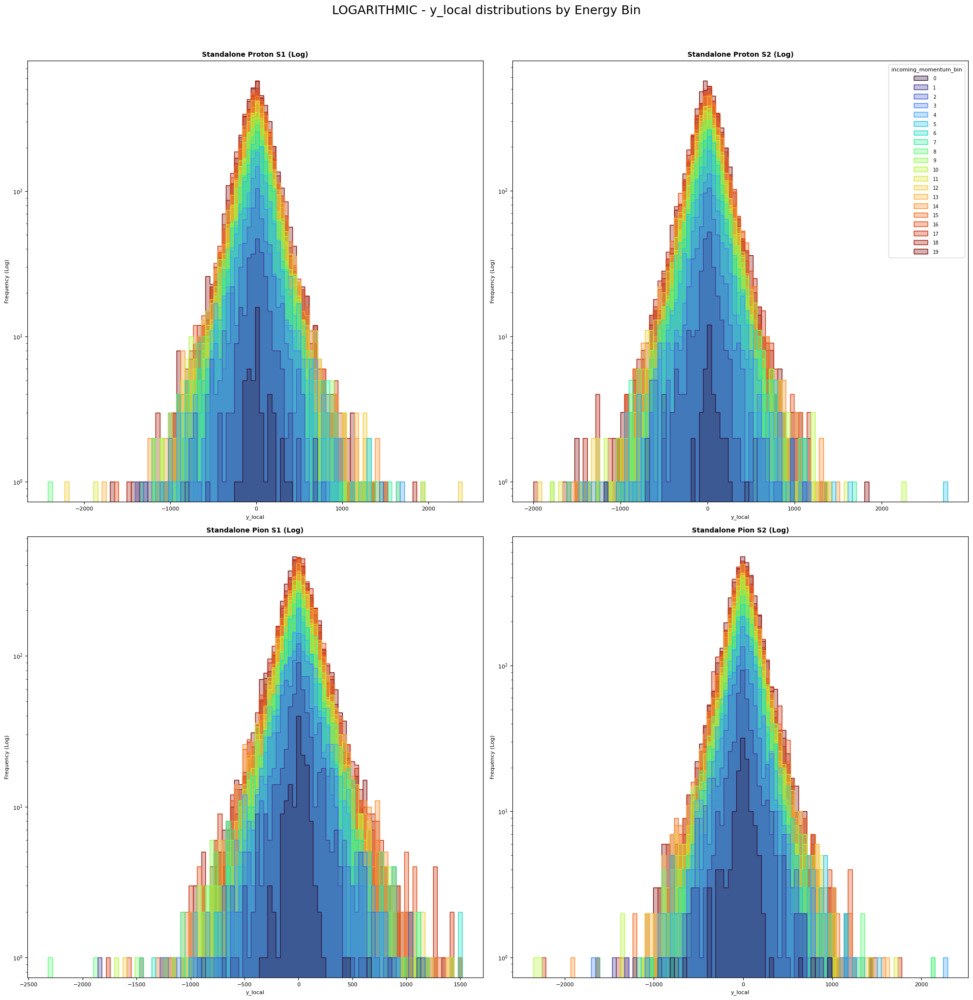

🚀 Logarithmic (Energy Bins):  29%|██▊       | 2/7 [00:19<00:48,  9.77s/it]

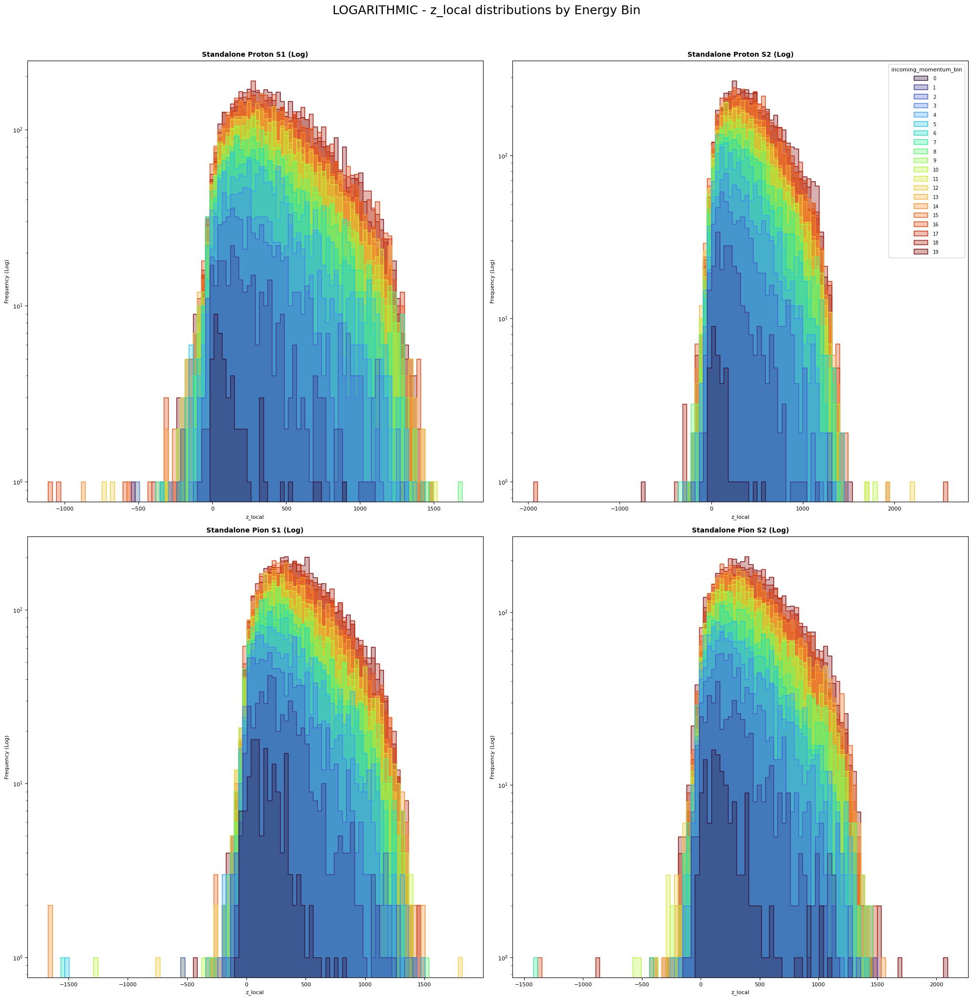

🚀 Logarithmic (Energy Bins):  43%|████▎     | 3/7 [00:28<00:37,  9.47s/it]

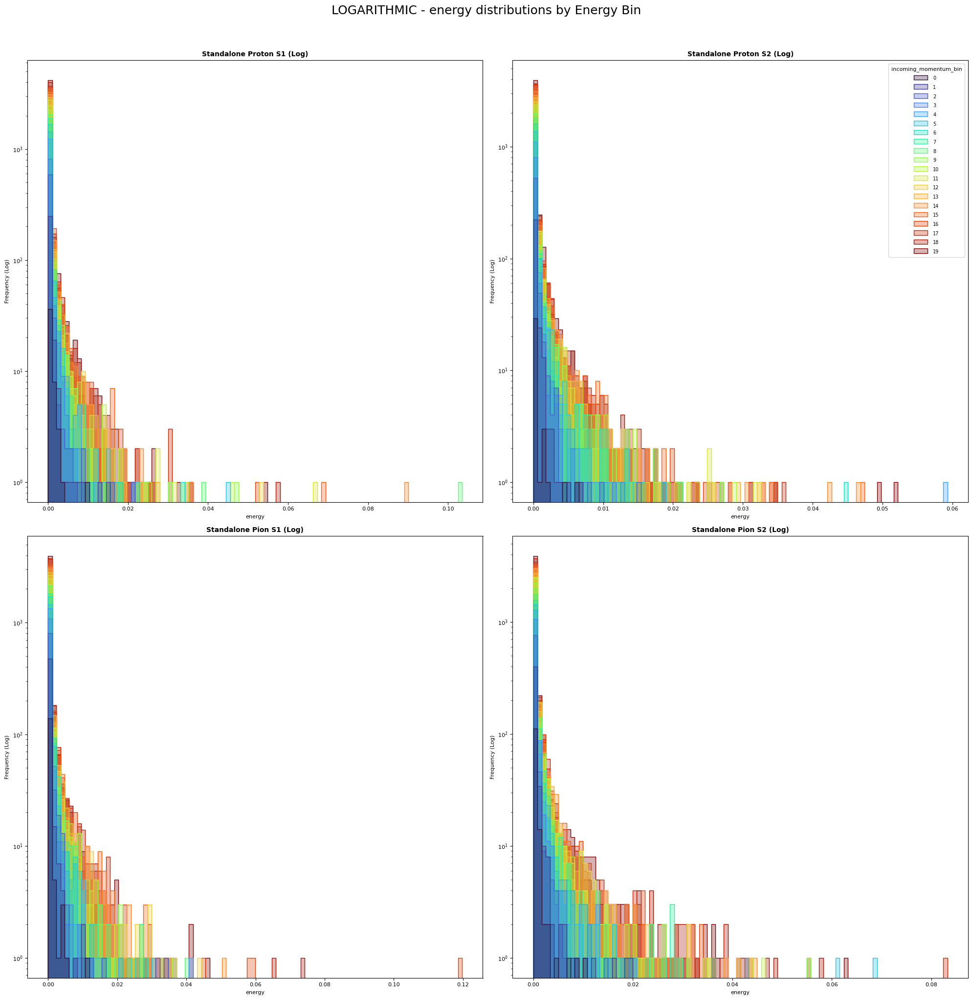

🚀 Logarithmic (Energy Bins):  57%|█████▋    | 4/7 [00:37<00:27,  9.31s/it]

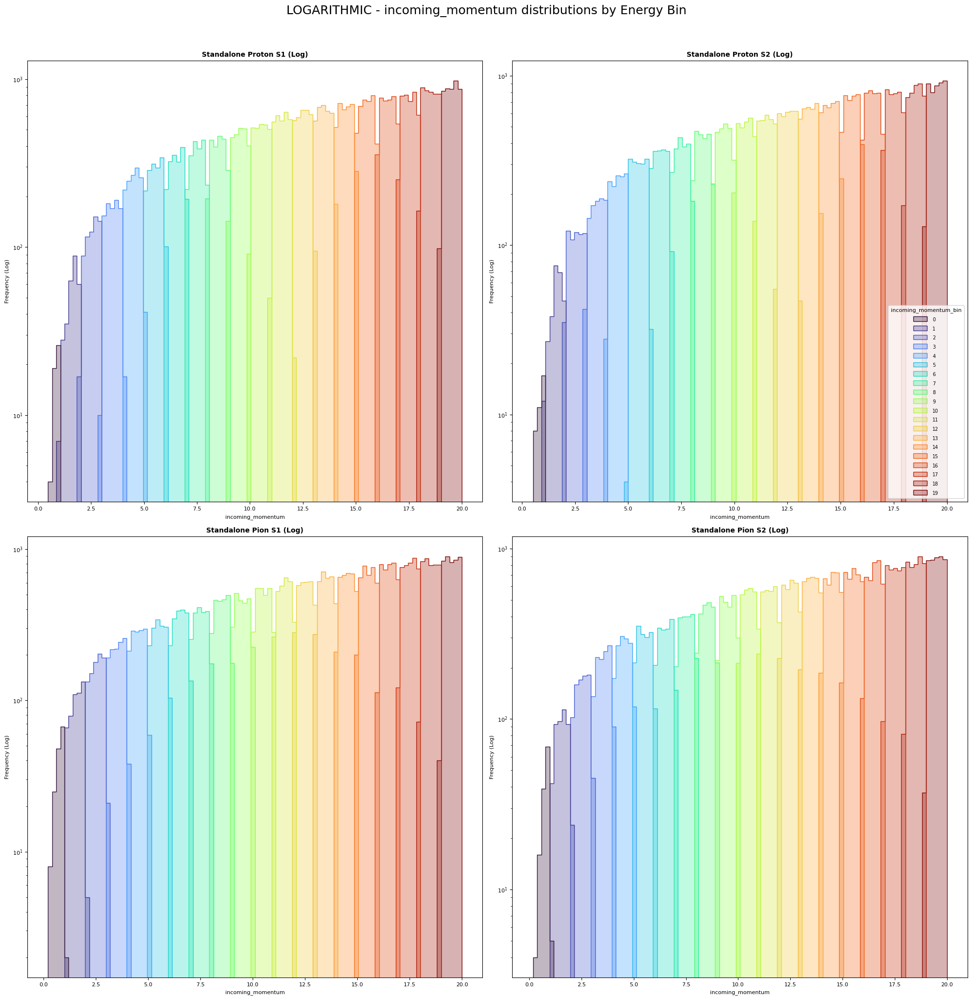

🚀 Logarithmic (Energy Bins):  71%|███████▏  | 5/7 [00:46<00:18,  9.21s/it]

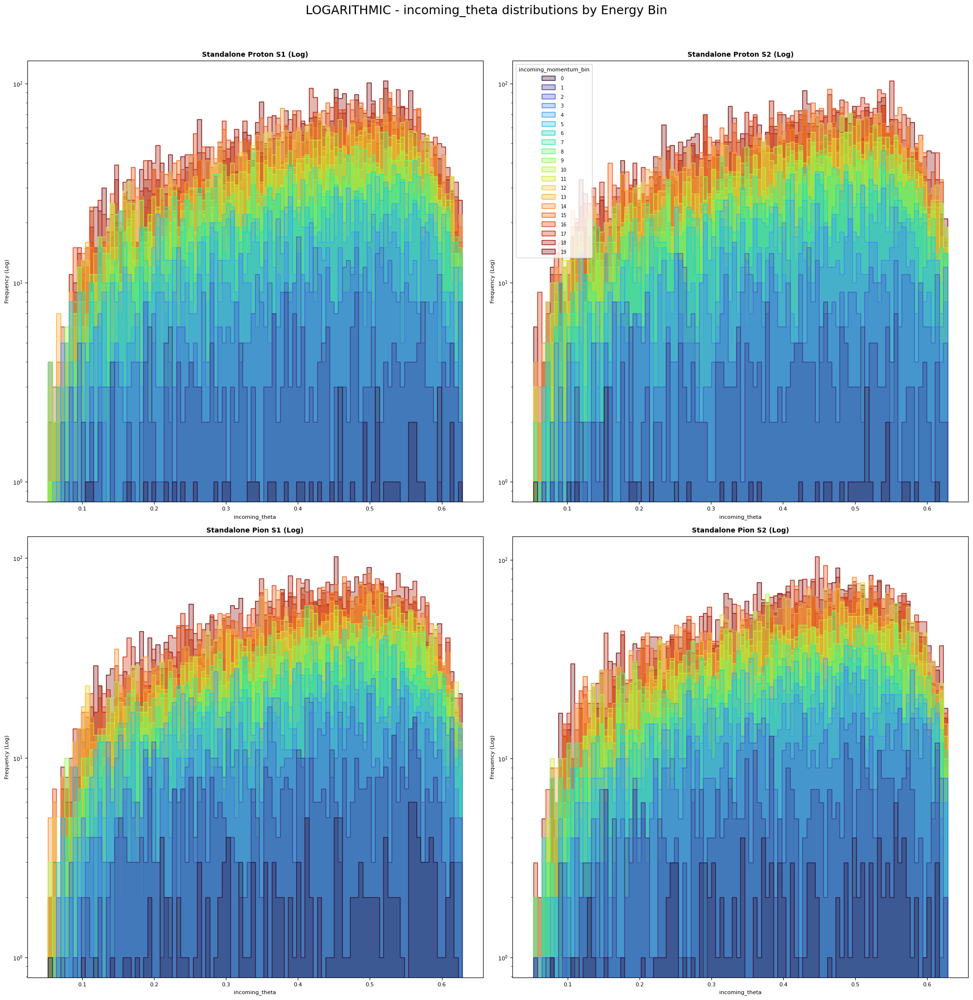

🚀 Logarithmic (Energy Bins):  86%|████████▌ | 6/7 [00:57<00:09,  9.64s/it]

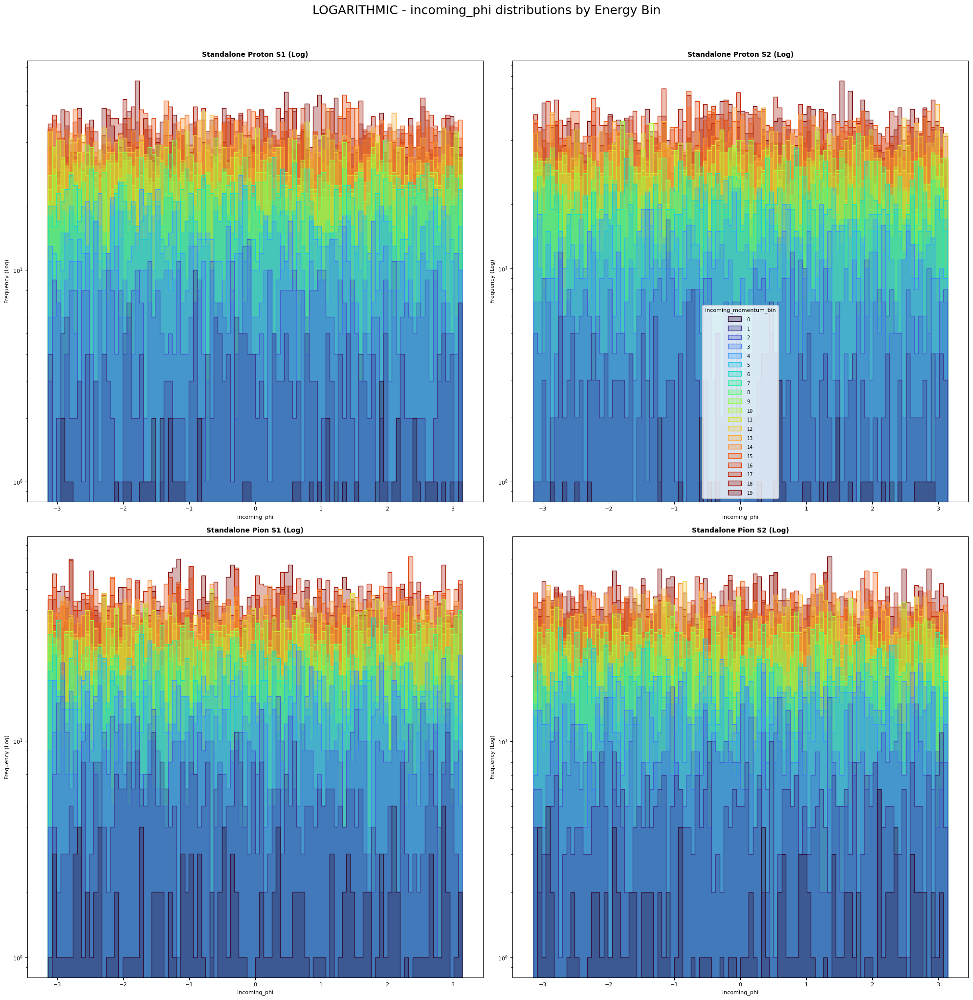

🚀 Logarithmic (Energy Bins): 100%|██████████| 7/7 [01:07<00:00,  9.68s/it]


In [13]:
#logarithmic distribution

for col in core.tqdm(columns_to_plot, desc="🚀 Logarithmic (Energy Bins)"):
    fig, axes = core.plt.subplots(2, 2, figsize=(20, 20))
    axes_flat = axes.flatten()

    for i, name in enumerate(all_names):
        ax = axes_flat[i]
        df = dataframes_local[name]

        cols_needed = [col, 'incoming_momentum_bin']
        data = df[cols_needed].dropna()
        sample = data.sample(min(len(data), 50000), random_state=42)

        core.sns.histplot(
            data=sample,
            x=col,
            hue='incoming_momentum_bin',
            element="step",
            palette="turbo",
            ax=ax,
            bins=100,
            alpha=0.3,
            legend=(i == 1)
        )

        # Logaritmikus skála beállítása
        ax.set_yscale('log')

        ax.set_title(f'{name} (Log)', fontsize=10, fontweight='bold')
        ax.tick_params(axis='both', labelsize=8)
        ax.set_xlabel(col, fontsize=8)
        ax.set_ylabel('Frequency (Log)', fontsize=8)

        if ax.get_legend():
            core.plt.setp(ax.get_legend().get_texts(), fontsize='7')
            core.plt.setp(ax.get_legend().get_title(), fontsize='8')

    fig.suptitle(f'LOGARITHMIC - {col} distributions by Energy Bin', fontsize=18, y=1.02)
    core.plt.tight_layout()
    core.plt.show()

3D visualization: extra, based on LFHCal presentation

In [14]:
#@title 3D plot

def plot_3d_shower_local(df, particle_label, event_number=None, marker_size=25, cmap='viridis'):
    """
    3D event display in the shower's local (already-rotated) frame - mirrors the
    LFHCal test-beam 'blue box' event displays (z' = depth along the shower axis).
    """
    if event_number is None:
        event_number = df.groupby('event_number').size().idxmax()

    evt = df[df['event_number'] == event_number]

    fig = core.plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')

    order = core.np.argsort(evt['energy'].to_numpy())
    evt = evt.iloc[order]

    p = ax.scatter(evt['z_local'], evt['x_local'], evt['y_local'],
                    c=evt['energy'], cmap=cmap, s=marker_size, marker='s', depthshade=True)

    ax.set_xlabel("Z' (depth, mm)")
    ax.set_ylabel("X' (mm)")
    ax.set_zlabel("Y' (mm)")

    momentum = float(evt['incoming_momentum'].iloc[0])
    primary_hits = evt[evt['is_secondary'] == 0]
    ptype = str(primary_hits['particle_type'].iloc[0]) if len(primary_hits) else "primary hit missing"
    ax.set_title(f"{particle_label} shower (local frame), event {event_number}\n"
                 f"{ptype}, p = {momentum:.2f} GeV \u2014 {len(evt)} hits")

    core.plt.colorbar(p, ax=ax, label='Deposited energy', shrink=0.6)
    core.plt.show()
    return event_number


In [15]:
#diagnostic for mislabelling error

has_primary = df_standalone_proton_s1.groupby('event_number')['is_secondary'].apply(lambda s: (s == 0).any())
total_events = len(has_primary)
missing_primary = (~has_primary).sum()
print(f"Total proton events: {total_events}")
print(f"Events with NO primary-tagged hit: {missing_primary}")
print(f"Percentage affected: {100 * missing_primary / total_events:.2f}%")
print(has_primary[~has_primary].index.tolist()[:10])


has_primary_pion = df_standalone_pion_s1.groupby('event_number')['is_secondary'].apply(lambda s: (s == 0).any())
total_events = len(has_primary_pion)
missing_primary = (~has_primary_pion).sum()
print(f"Total pion events: {total_events}")
print(f"Events with NO primary-tagged hit: {missing_primary}")
print(f"Percentage affected: {100 * missing_primary / total_events:.2f}%")
print(has_primary_pion[~has_primary_pion].index.tolist()[:10])

Total proton events: 100000
Events with NO primary-tagged hit: 27392
Percentage affected: 27.39%
[24, 33, 37, 44, 64, 77, 78, 82, 92, 104]
Total pion events: 100000
Events with NO primary-tagged hit: 25350
Percentage affected: 25.35%
[15, 16, 21, 25, 39, 53, 58, 73, 82, 83]


In [16]:
#@title 3D plot colorized by secondary particle type

from matplotlib.lines import Line2D  # already imported earlier in the notebook, listed here for standalone use

def plot_3d_shower_colorized_secondaries(df, particle_label, event_number=None,
                                          marker_size=25, cmap_name='tab20'):
    """
    3D event display in the shower's local (already-rotated) frame, colored by
    particle_type per hit instead of energy - shows how many distinct secondary
    species show up, and where they cluster, as the shower develops along depth (z_local).
    Primary-tagged hits (is_secondary == 0) get a black edge so they stay visually
    distinct from secondaries of the same species.
    """
    if event_number is None:
        event_number = df.groupby('event_number').size().idxmax()

    evt = df[df['event_number'] == event_number].copy()

    # draw in energy order so brighter hits aren't buried under dim ones
    order = core.np.argsort(evt['energy'].to_numpy())
    evt = evt.iloc[order].reset_index(drop=True)

    fig = core.plt.figure(figsize=(11, 8))
    ax = fig.add_subplot(111, projection='3d')

    species = evt['particle_type'].astype(str)
    unique_species = sorted(species.unique())
    cmap = core.plt.get_cmap(cmap_name, max(len(unique_species), 1))
    species_to_color = {s: cmap(i) for i, s in enumerate(unique_species)}
    point_colors = species.map(species_to_color)

    is_primary = (evt['is_secondary'] == 0).to_numpy()

    # secondaries first, primaries drawn on top with a black edge
    ax.scatter(evt['z_local'][~is_primary], evt['x_local'][~is_primary], evt['y_local'][~is_primary],
               c=list(point_colors[~is_primary]), s=marker_size, marker='s', depthshade=True,
               linewidths=0)
    ax.scatter(evt['z_local'][is_primary], evt['x_local'][is_primary], evt['y_local'][is_primary],
               c=list(point_colors[is_primary]), s=marker_size * 1.4, marker='s', depthshade=True,
               edgecolors='black', linewidths=0.6)

    ax.set_xlabel("Z' (depth, mm)")
    ax.set_ylabel("X' (mm)")
    ax.set_zlabel("Y' (mm)")

    momentum = float(evt['incoming_momentum'].iloc[0])
    primary_hits = evt[evt['is_secondary'] == 0]
    ptype = str(primary_hits['particle_type'].iloc[0]) if len(primary_hits) else "primary hit missing"
    ax.set_title(f"{particle_label} shower (local frame), event {event_number}\n"
                 f"{ptype}, p = {momentum:.2f} GeV — {len(evt)} hits, {len(unique_species)} particle species\n"
                 f"(black edge = primary-tagged hit)")

    legend_handles = [
        Line2D([0], [0], marker='s', linestyle='', markerfacecolor=species_to_color[s],
               markeredgecolor='black', markersize=9, label=s)
        for s in unique_species
    ]
    ax.legend(handles=legend_handles, title='particle_type', loc='upper left', bbox_to_anchor=(1.05, 1.0))

    core.plt.tight_layout()
    core.plt.show()
    return event_number

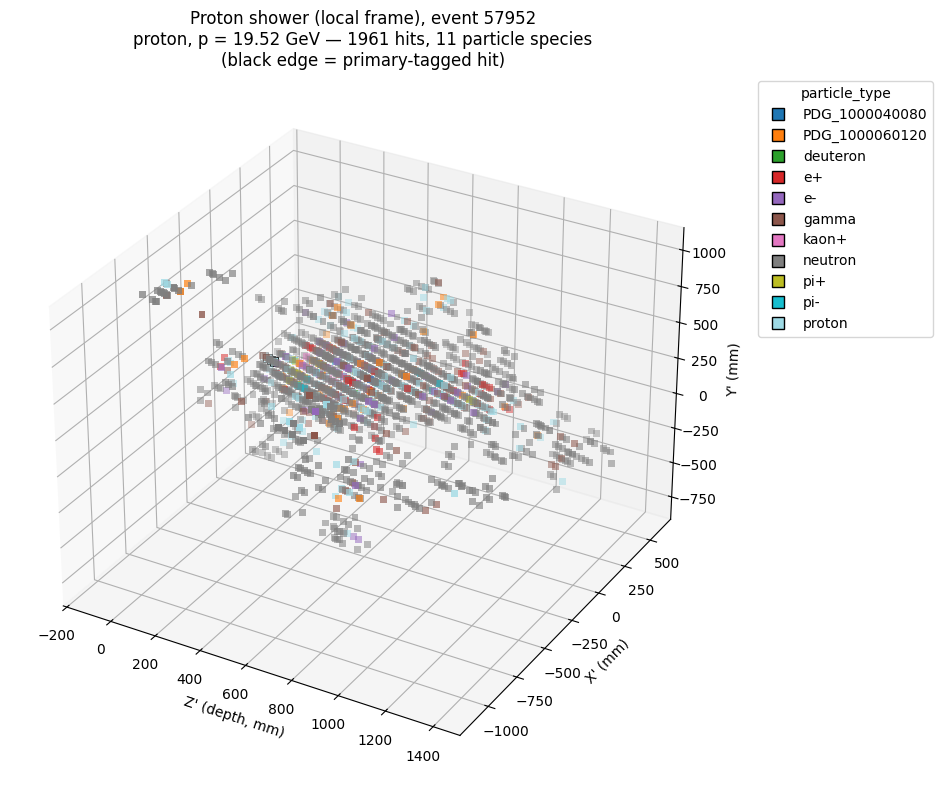

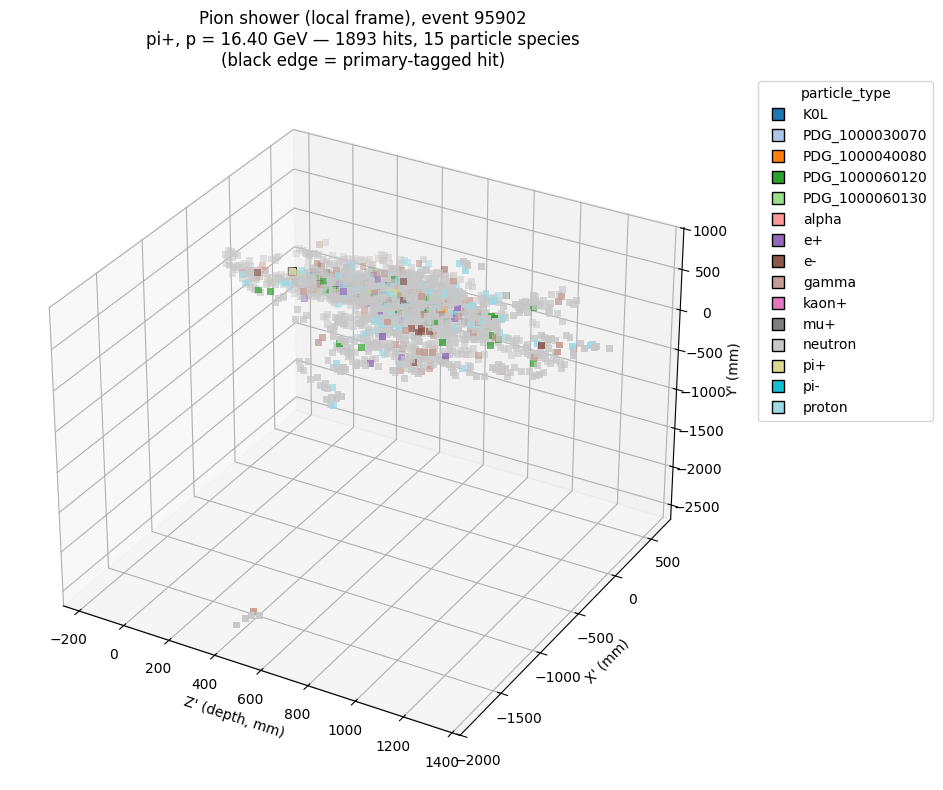

In [17]:
ev_proton = plot_3d_shower_colorized_secondaries(df_standalone_proton_s1, "Proton")
ev_pion = plot_3d_shower_colorized_secondaries(df_standalone_pion_s1, "Pion")

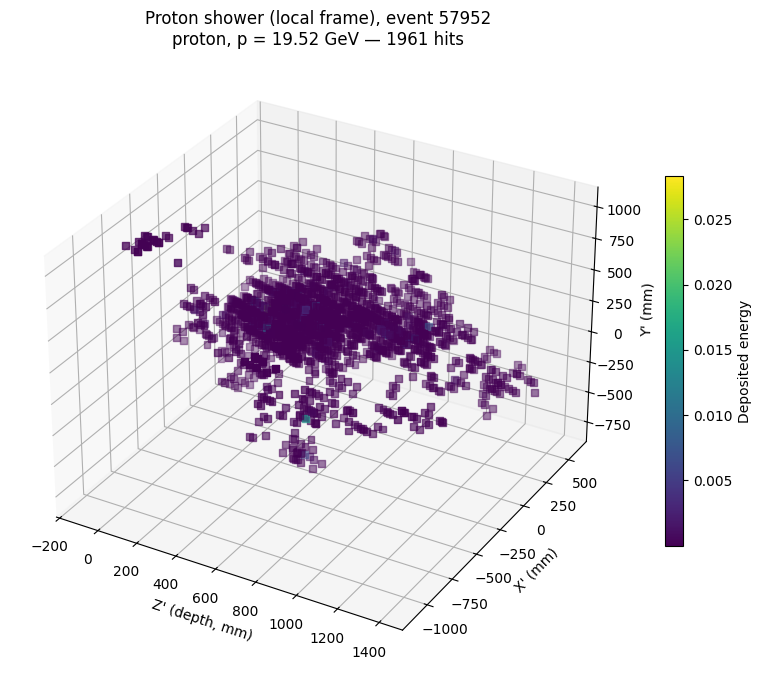

In [18]:
ev_proton = plot_3d_shower_local(df_standalone_proton_s1, "Proton")

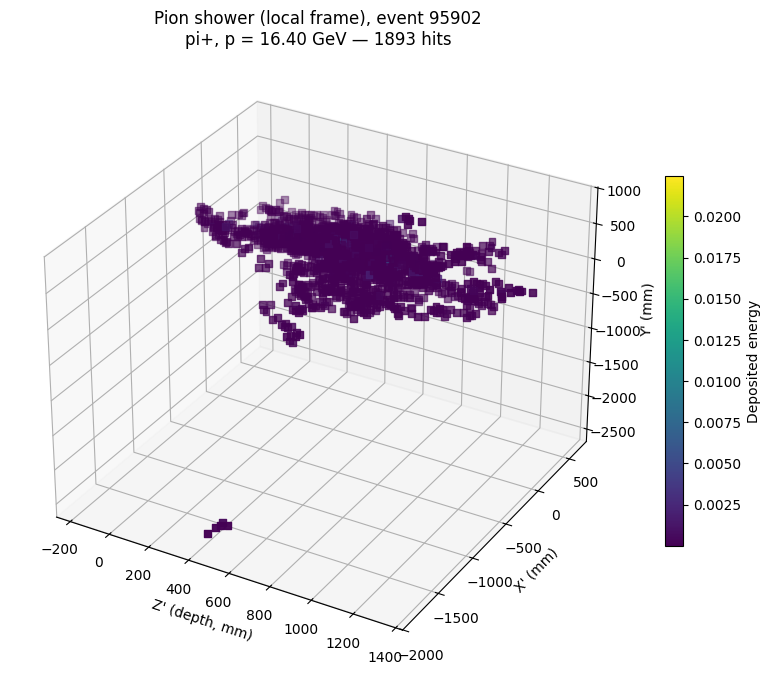

In [19]:
ev_pion = plot_3d_shower_local(df_standalone_pion_s1, "Pion")

Extra plot: Longitudinal/Radial shower profiles of protons and pions based on the LFHCal presentation (Energy deposit per cm (%) vs depth, radius)

In [20]:
#@Title longitudinal/radial profiles


def plot_shower_profiles(df, particle_label, z_bin_width_mm=20, r_bin_width_mm=10,
                          z_max_mm=1200, r_max_mm=300):

    df_pos = df[df['z_local'] >= 0].copy()
    df_pos['r_local'] = core.np.sqrt(df_pos['x_local'] ** 2 + df_pos['y_local'] ** 2)

    total_energy = df_pos['energy'].sum()

    z_bins = core.np.arange(0, z_max_mm + z_bin_width_mm, z_bin_width_mm)
    z_energy, _ = core.np.histogram(df_pos['z_local'], bins=z_bins, weights=df_pos['energy'])
    z_pct_per_cm = 100 * z_energy / total_energy / (z_bin_width_mm / 10)

    r_bins = core.np.arange(0, r_max_mm + r_bin_width_mm, r_bin_width_mm)
    r_energy, _ = core.np.histogram(df_pos['r_local'], bins=r_bins, weights=df_pos['energy'])
    r_pct_per_cm = 100 * r_energy / total_energy / (r_bin_width_mm / 10)

    fig, axes = core.plt.subplots(1, 2, figsize=(14, 5))

    axes[0].step(z_bins[:-1] / 10, z_pct_per_cm, where='post', color='red')
    axes[0].set_xlabel('Depth (cm)')
    axes[0].set_ylabel('Energy deposit per cm (%)')
    axes[0].set_title(f'Longitudinal shower profile ({particle_label})')
    axes[0].grid(alpha=0.3)

    axes[1].step(r_bins[:-1] / 10, r_pct_per_cm, where='post', color='red')
    axes[1].set_xlabel('Radius (cm)')
    axes[1].set_ylabel('Energy deposit per cm (%)')
    axes[1].set_title(f'Radial shower profile ({particle_label})')
    axes[1].grid(alpha=0.3)

    core.plt.tight_layout()
    core.plt.show()


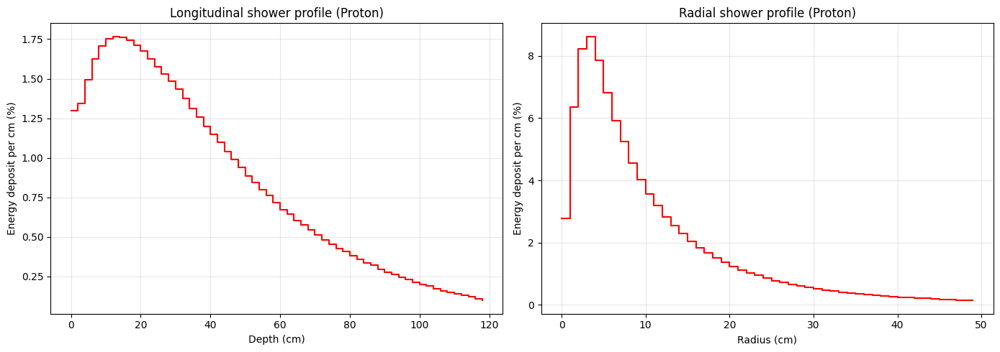

In [21]:
plot_shower_profiles(df_standalone_proton_s1, "Proton", z_max_mm=1200, r_max_mm=500)

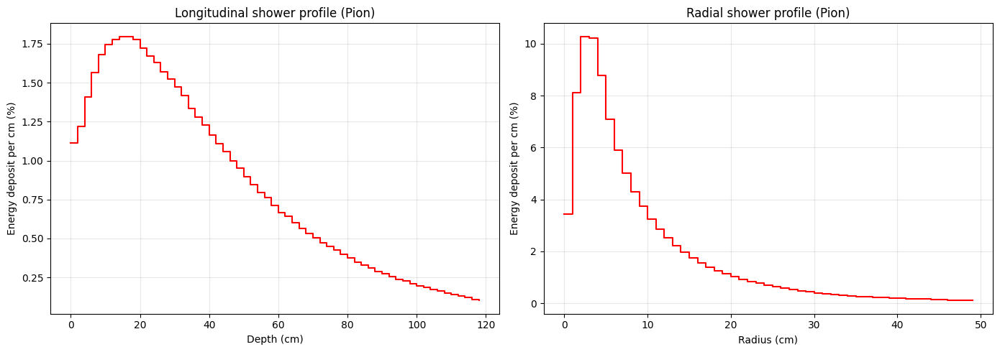

In [22]:
plot_shower_profiles(df_standalone_pion_s1, "Pion", z_max_mm=1200, r_max_mm=500)
# NOTE: same starting values as proton — check the output and narrow r_max_mm/z_max_mm if the
# pion profile turns out tighter or wider.

Pearson heatmap recomputed on local coordinates

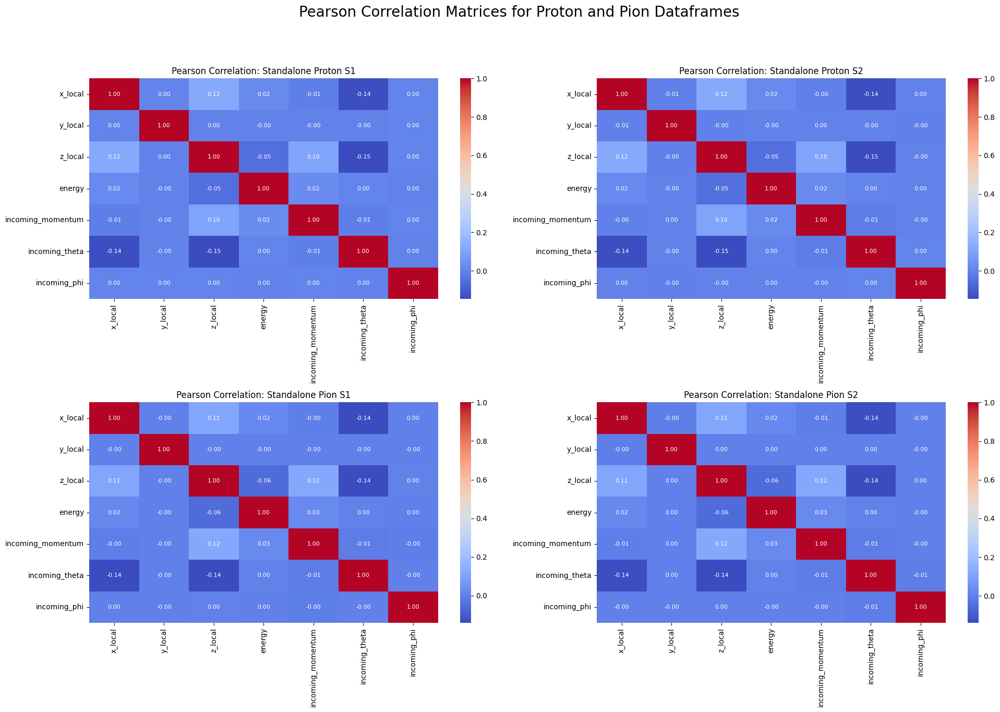

In [23]:
dataframes = {
    'Standalone Proton S1': df_standalone_proton_s1,
    'Standalone Proton S2': df_standalone_proton_s2,
    'Standalone Pion S1': df_standalone_pion_s1,
    'Standalone Pion S2': df_standalone_pion_s2,
}

all_names = [
    'Standalone Proton S1', 'Standalone Proton S2',
    'Standalone Pion S1', 'Standalone Pion S2',
]

corr_columns = ['x_local', 'y_local', 'z_local', 'energy',
                'incoming_momentum', 'incoming_theta', 'incoming_phi']

fig, axes = core.plt.subplots(2, 2, figsize=(20, 20))

axes_flat = axes.flatten()

for i, name in enumerate(all_names):
    df = dataframes[name]
    correlation_matrix = df[corr_columns].corr(method='pearson', numeric_only=True)

    core.sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", ax=axes_flat[i], annot_kws={"size": 8})

    axes_flat[i].set_title(f'Pearson Correlation: {name}')
    axes_flat[i].tick_params(axis='x', rotation=90)
    axes_flat[i].tick_params(axis='y', rotation=0)

fig.suptitle('Pearson Correlation Matrices for Proton and Pion Dataframes', fontsize=20)
core.plt.tight_layout(rect=[0, 0.3, 1, 0.95])
core.plt.show()

In [24]:
def diagnose_negative_z(df, label, z_col='z_local', max_examples=10, tol_mm=1e-6):
    """
    tol_mm: anything between -tol_mm and 0 is floating-point noise, not a real
    negative depth - 1e-6 mm is ~10 orders of magnitude below the 50mm sensor
    size, so it only filters rounding dust, not genuine negative-z hits.
    """
    total_events = df['event_number'].nunique()

    raw_affected = (df[z_col] < 0).groupby(df['event_number']).any().sum()
    real_mask = df[z_col] < -tol_mm
    real_affected_events = sorted(df.loc[real_mask, 'event_number'].unique())
    n_real = len(real_affected_events)

    print(f"=== {label}: negative {z_col} check ===")
    print(f"Total events: {total_events}")
    print(f"Events with ANY negative hit (incl. float dust): {raw_affected} ({100*raw_affected/total_events:.2f}%)")
    print(f"Events with a MEANINGFULLY negative hit (< -{tol_mm} mm): {n_real} ({100*n_real/total_events:.2f}%)")
    print(f"Example meaningfully-affected event numbers: {real_affected_events[:max_examples]}")

    detail = (
        df[df['event_number'].isin(real_affected_events)]
        .groupby('event_number')
        .apply(lambda g: core.pd.Series({
            'n_hits': len(g),
            'n_negative_z': int((g[z_col] < -tol_mm).sum()),
            'frac_negative_z': (g[z_col] < -tol_mm).mean(),
            'min_z': g[z_col].min(),
        }))
        .sort_values('frac_negative_z', ascending=False)
    )
    return real_affected_events, detail

In [25]:
affected_proton, detail_proton = diagnose_negative_z(df_standalone_proton_s1, "Proton")
detail_proton.head(10)
affected_pion, detail_pion = diagnose_negative_z(df_standalone_pion_s1, "Pion")
detail_pion.head(10)

=== Proton: negative z_local check ===
Total events: 100000
Events with ANY negative hit (incl. float dust): 81704 (81.70%)
Events with a MEANINGFULLY negative hit (< -1e-06 mm): 79764 (79.76%)
Example meaningfully-affected event numbers: [np.int64(18), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(29), np.int64(30), np.int64(33), np.int64(35), np.int64(37)]


/tmp/ipykernel_3214918/238717437.py:23: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: core.pd.Series({


=== Pion: negative z_local check ===
Total events: 100000
Events with ANY negative hit (incl. float dust): 77427 (77.43%)
Events with a MEANINGFULLY negative hit (< -1e-06 mm): 74858 (74.86%)
Example meaningfully-affected event numbers: [np.int64(0), np.int64(1), np.int64(6), np.int64(15), np.int64(16), np.int64(17), np.int64(21), np.int64(23), np.int64(25), np.int64(26)]


/tmp/ipykernel_3214918/238717437.py:23: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: core.pd.Series({


,n_hits,n_negative_z,frac_negative_z,min_z
event_number,,,,
167245,27.0,26.0,0.962963,-1441.540859
180020,12.0,11.0,0.916667,-154.653400
66836,8.0,7.0,0.875000,-157.102381
112313,8.0,7.0,0.875000,-90.536232
180347,8.0,7.0,0.875000,-80.767426
158756,7.0,6.0,0.857143,-123.104895
208017,7.0,6.0,0.857143,-95.566742
36546,20.0,17.0,0.850000,-142.487904
72587,19.0,16.0,0.842105,-173.899539


In [26]:
for name, detail in [("Proton", detail_proton), ("Pion", detail_pion)]:
    print(f"=== {name}: frac_negative_z distribution across affected events ===")
    print(detail['frac_negative_z'].describe())
    mostly_negative = (detail['frac_negative_z'] > 0.5).sum()
    print(f"Affected events where >50% of hits are negative: {mostly_negative} / {len(detail)} "
          f"({100*mostly_negative/len(detail):.1f}%)")

=== Proton: frac_negative_z distribution across affected events ===
count    79764.000000
mean         0.042012
std          0.059015
min          0.000586
25%          0.008264
50%          0.023196
75%          0.052632
max          0.900000
Name: frac_negative_z, dtype: float64
Affected events where >50% of hits are negative: 120 / 79764 (0.2%)
=== Pion: frac_negative_z distribution across affected events ===
count    74858.000000
mean         0.039610
std          0.057026
min          0.000575
25%          0.007299
50%          0.020979
75%          0.048780
max          0.962963
Name: frac_negative_z, dtype: float64
Affected events where >50% of hits are negative: 91 / 74858 (0.1%)


In [27]:
def plot_negative_z_by_energy(df, particle_label, energy_col='incoming_momentum',
                               low_cut=1.0, high_cut=10.0,
                               max_shower_radius=500, max_shower_length=1200):
    """
    events below low_cut GeV and events above high_cut GeV.
   
    """
    low_df = df[df[energy_col] < low_cut]
    high_df = df[df[energy_col] > high_cut]

    n_ev = lambda d: d['event_number'].nunique()
    print(f"{particle_label}: < {low_cut} GeV -> {n_ev(low_df)} events, {len(low_df)} hits")
    print(f"{particle_label}: > {high_cut} GeV -> {n_ev(high_df)} events, {len(high_df)} hits")

    print(f"\n=== {particle_label}: LOW energy (< {low_cut} GeV) ===")
    visualize_superimposed_vs_global(low_df, max_shower_radius=max_shower_radius,
                                      max_shower_length=max_shower_length)

    print(f"\n=== {particle_label}: HIGH energy (> {high_cut} GeV) ===")
    visualize_superimposed_vs_global(high_df, max_shower_radius=max_shower_radius,
                                      max_shower_length=max_shower_length)

    return low_df, high_df

Proton: < 1.0 GeV -> 5000 events, 48041 hits
Proton: > 10.0 GeV -> 50000 events, 40072182 hits

=== Proton: LOW energy (< 1.0 GeV) ===


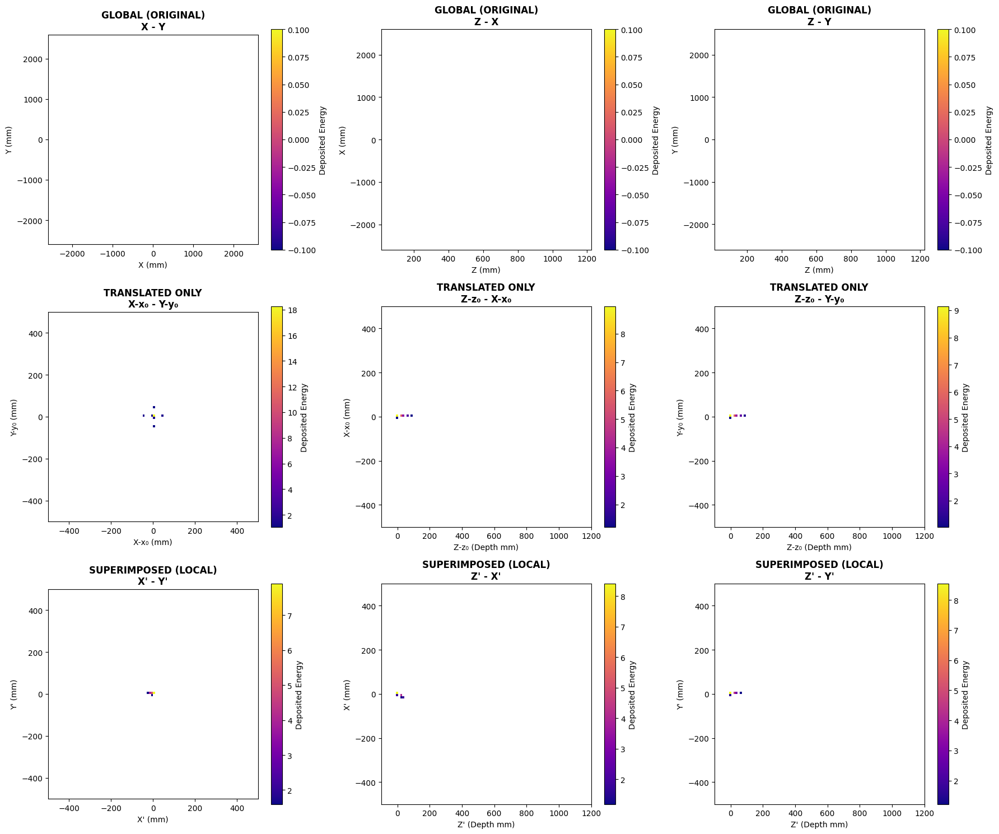


=== Proton: HIGH energy (> 10.0 GeV) ===


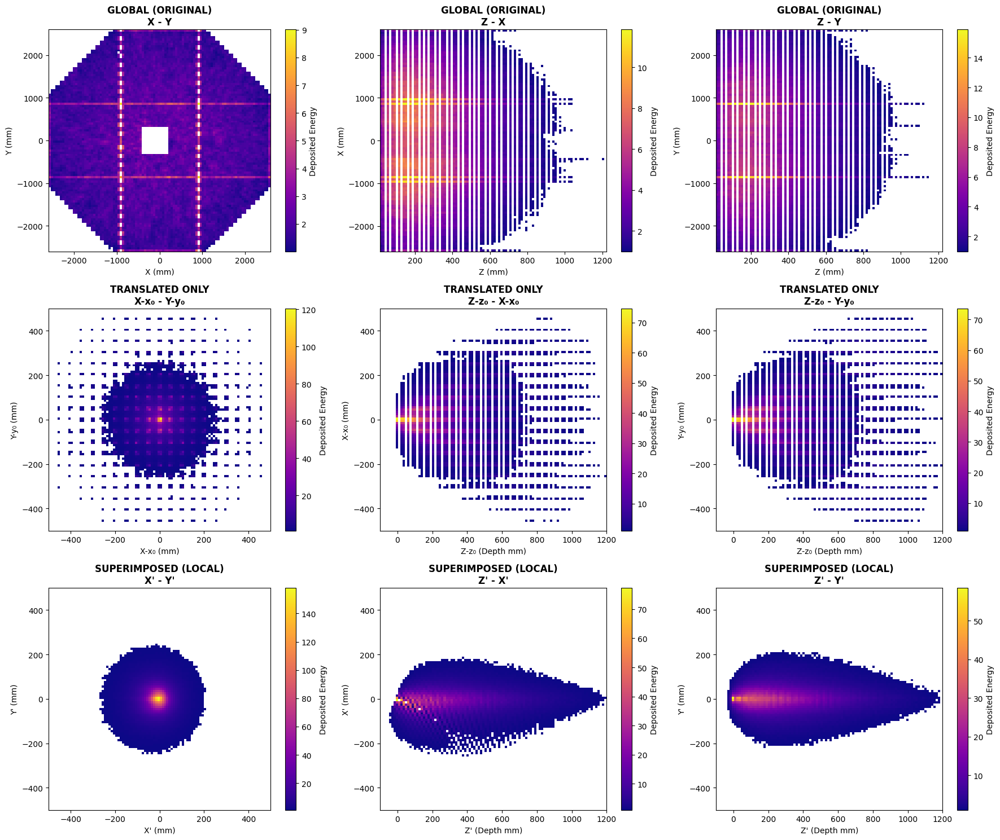

Pion: < 1.0 GeV -> 5000 events, 150251 hits
Pion: > 10.0 GeV -> 50000 events, 34945540 hits

=== Pion: LOW energy (< 1.0 GeV) ===


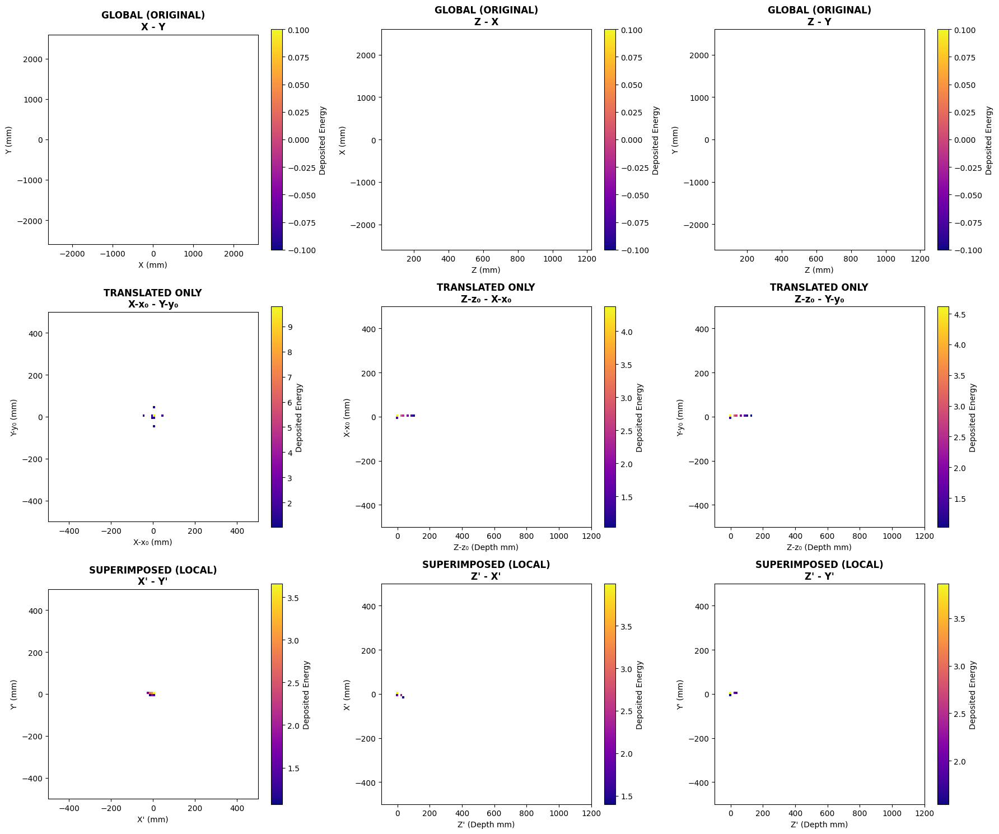


=== Pion: HIGH energy (> 10.0 GeV) ===


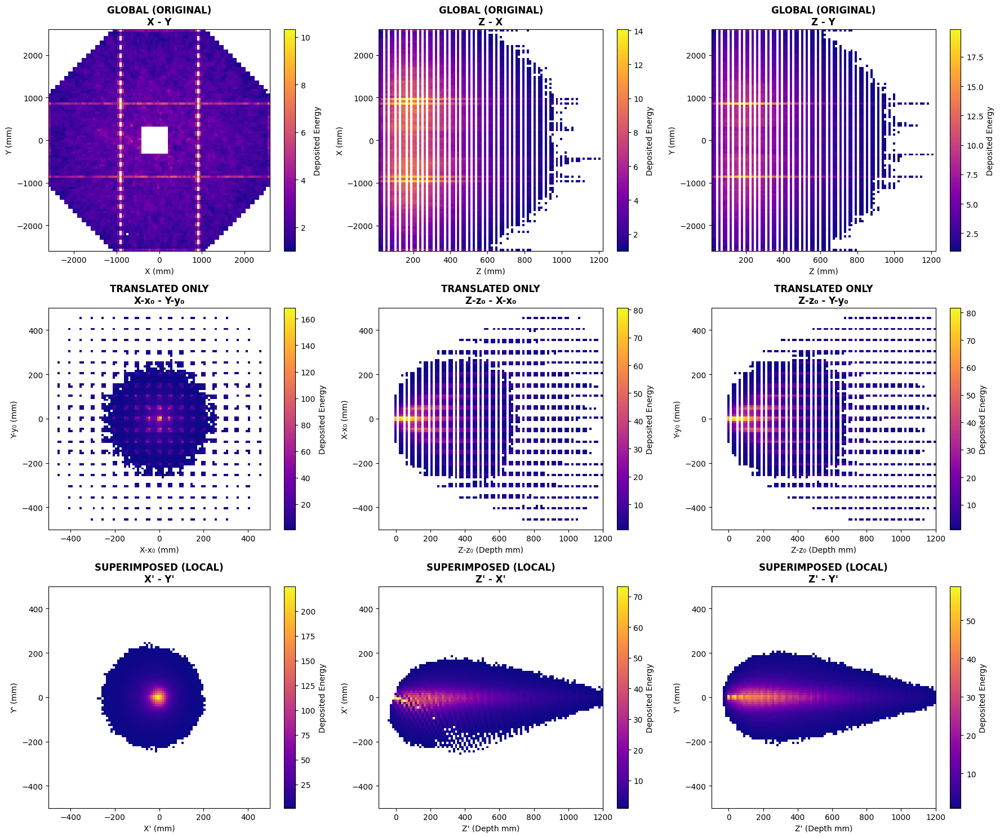

(          event_number      cellID            x            y           z  \
 20              107591  1640270964  1344.261963   733.200012   74.899902   
 491               2728   571116660  1489.072021 -1541.199951  136.399902   
 643             106177  1707567220 -1383.126953  -276.799988  279.899902   
 682              62386    58935156  1897.254028  1238.199951  115.899902   
 855             101294  1074061940  -632.651001   680.799988   54.399902   
 ...                ...         ...          ...          ...         ...   
 49110175        127520  2860523892  -628.245972  2599.800049  935.899902   
 49110401         98610  1619695220   383.087006 -1541.199951   74.899902   
 49110557        165839  1183344244 -1132.968018  -632.200012  464.399902   
 49110779         84228  1657357684  2050.873047 -1036.199951  177.399902   
 49110881         65743   117694068  -228.873001  1036.199951  423.399902   
 
              x_local     y_local     z_local     x_trans     y_trans  ...

In [28]:
# proton/pion case
plot_negative_z_by_energy(df_standalone_proton_s1, "Proton")
plot_negative_z_by_energy(df_standalone_pion_s1, "Pion")

Proton: < 1.0 GeV -> 5000 events, 48041 hits
Proton: > 10.0 GeV -> 50000 events, 40072182 hits

=== Proton: LOW energy (< 1.0 GeV) ===


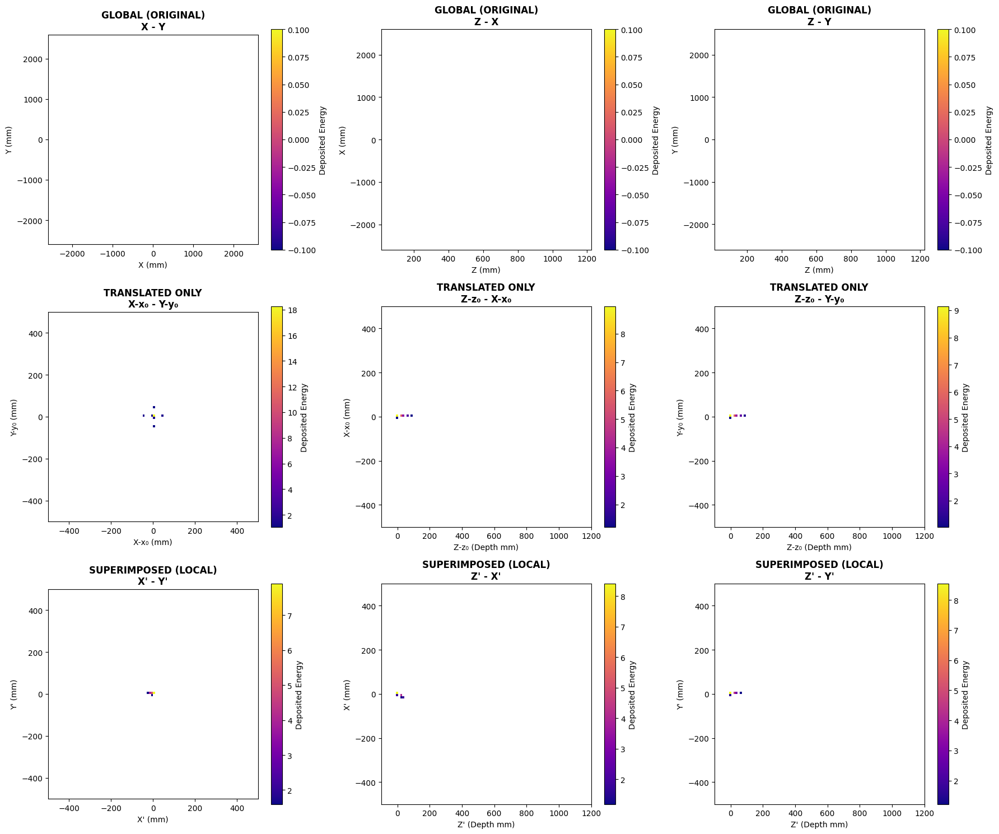


=== Proton: HIGH energy (> 10.0 GeV) ===


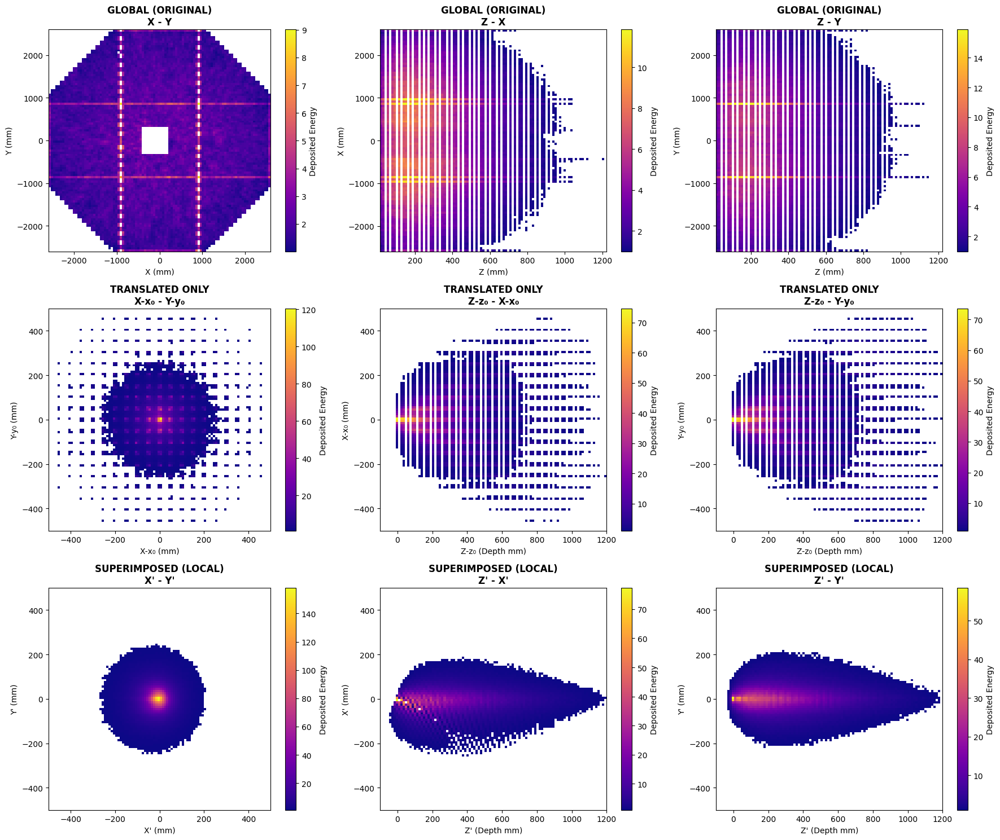

=== Proton (< 1 GeV): negative z_local check ===
Total events: 5000
Events with ANY negative hit (incl. float dust): 1714 (34.28%)
Events with a MEANINGFULLY negative hit (< -1e-06 mm): 1416 (28.32%)
Example meaningfully-affected event numbers: [np.int64(524), np.int64(665), np.int64(723), np.int64(1108), np.int64(1409), np.int64(2483), np.int64(3150), np.int64(3670), np.int64(3750), np.int64(3789)]


/tmp/ipykernel_3214918/238717437.py:23: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: core.pd.Series({


=== Proton (> 10 GeV): negative z_local check ===
Total events: 50000
Events with ANY negative hit (incl. float dust): 44151 (88.30%)
Events with a MEANINGFULLY negative hit (< -1e-06 mm): 43478 (86.96%)
Example meaningfully-affected event numbers: [np.int64(18), np.int64(21), np.int64(22), np.int64(23), np.int64(37), np.int64(43), np.int64(44), np.int64(48), np.int64(52), np.int64(57)]


/tmp/ipykernel_3214918/238717437.py:23: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: core.pd.Series({


([np.int64(18),
  np.int64(21),
  np.int64(22),
  np.int64(23),
  np.int64(37),
  np.int64(43),
  np.int64(44),
  np.int64(48),
  np.int64(52),
  np.int64(57),
  np.int64(62),
  np.int64(74),
  np.int64(78),
  np.int64(81),
  np.int64(89),
  np.int64(91),
  np.int64(92),
  np.int64(93),
  np.int64(98),
  np.int64(107),
  np.int64(109),
  np.int64(111),
  np.int64(114),
  np.int64(117),
  np.int64(140),
  np.int64(161),
  np.int64(162),
  np.int64(166),
  np.int64(171),
  np.int64(174),
  np.int64(177),
  np.int64(185),
  np.int64(188),
  np.int64(194),
  np.int64(199),
  np.int64(208),
  np.int64(215),
  np.int64(216),
  np.int64(218),
  np.int64(221),
  np.int64(223),
  np.int64(224),
  np.int64(225),
  np.int64(226),
  np.int64(232),
  np.int64(246),
  np.int64(249),
  np.int64(257),
  np.int64(259),
  np.int64(260),
  np.int64(261),
  np.int64(265),
  np.int64(271),
  np.int64(276),
  np.int64(284),
  np.int64(287),
  np.int64(288),
  np.int64(292),
  np.int64(295),
  np.int64(297),

In [29]:
low_df, high_df = plot_negative_z_by_energy(df_standalone_proton_s1, "Proton")

diagnose_negative_z(low_df, "Proton (< 1 GeV)")
diagnose_negative_z(high_df, "Proton (> 10 GeV)")

Pion: < 1.0 GeV -> 5000 events, 150251 hits
Pion: > 10.0 GeV -> 50000 events, 34945540 hits

=== Pion: LOW energy (< 1.0 GeV) ===


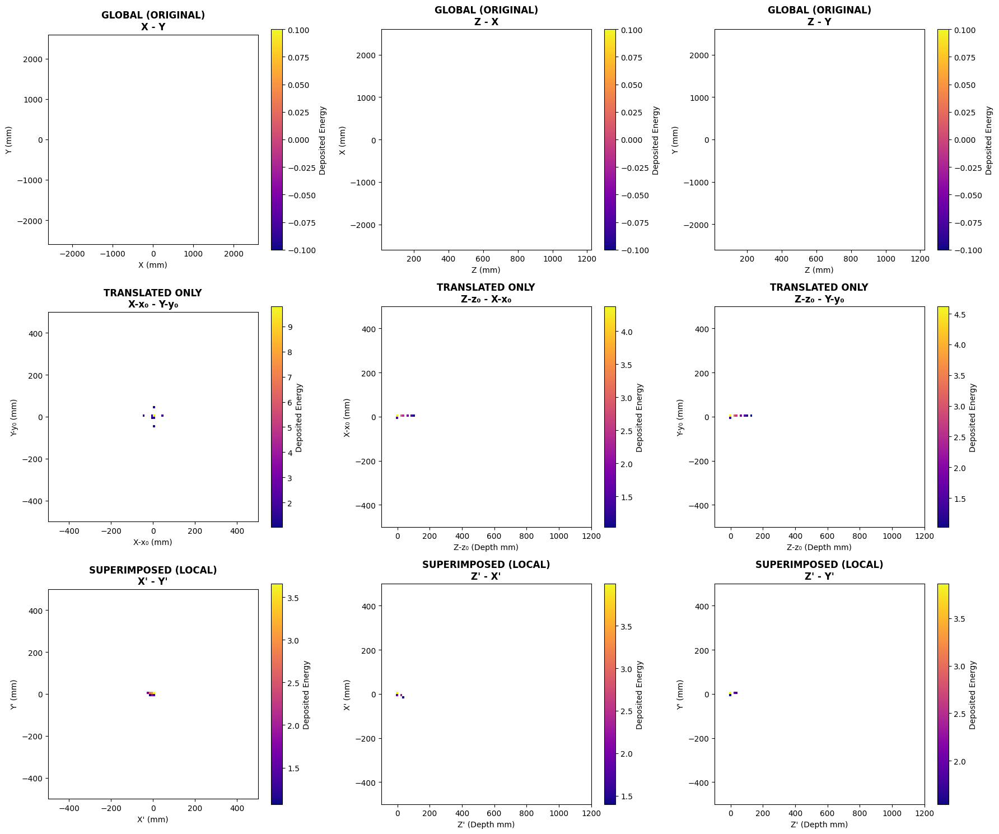


=== Pion: HIGH energy (> 10.0 GeV) ===


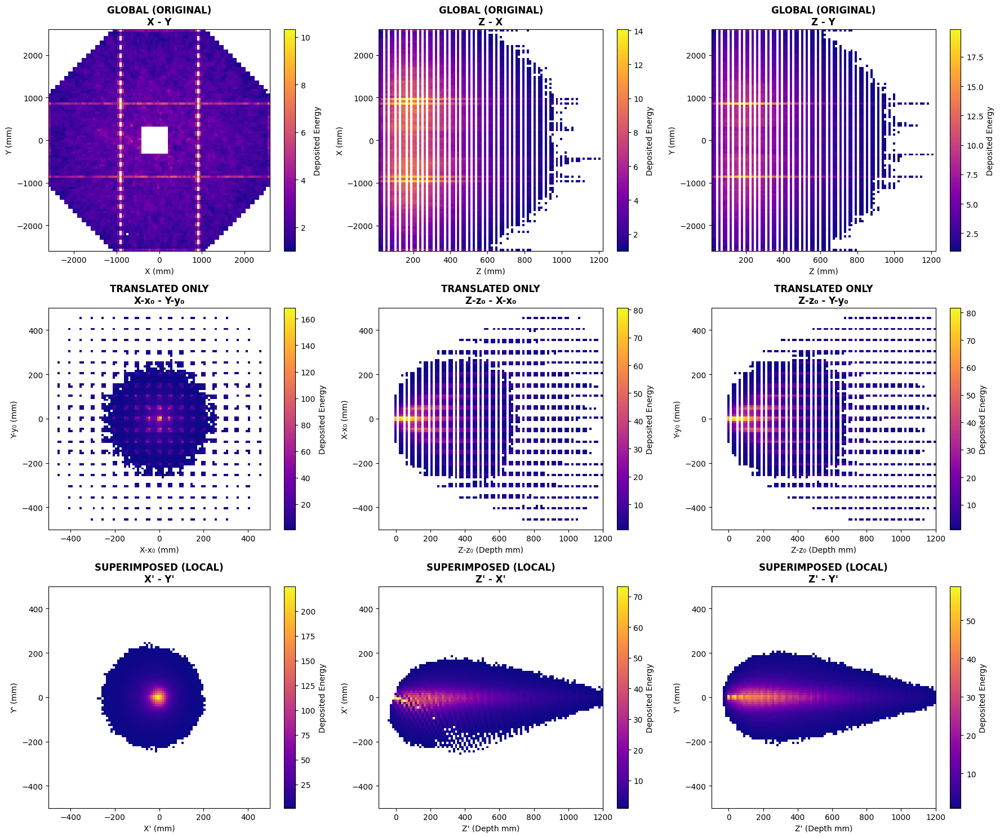

=== Pion (< 1 GeV): negative z_local check ===
Total events: 5000
Events with ANY negative hit (incl. float dust): 2510 (50.20%)
Events with a MEANINGFULLY negative hit (< -1e-06 mm): 2270 (45.40%)
Example meaningfully-affected event numbers: [np.int64(25), np.int64(26), np.int64(43), np.int64(79), np.int64(82), np.int64(97), np.int64(106), np.int64(437), np.int64(491), np.int64(695)]


/tmp/ipykernel_3214918/238717437.py:23: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: core.pd.Series({


=== Pion (> 10 GeV): negative z_local check ===
Total events: 50000
Events with ANY negative hit (incl. float dust): 40548 (81.10%)
Events with a MEANINGFULLY negative hit (< -1e-06 mm): 39470 (78.94%)
Example meaningfully-affected event numbers: [np.int64(0), np.int64(1), np.int64(17), np.int64(21), np.int64(23), np.int64(29), np.int64(30), np.int64(32), np.int64(33), np.int64(39)]


/tmp/ipykernel_3214918/238717437.py:23: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: core.pd.Series({


([np.int64(0),
  np.int64(1),
  np.int64(17),
  np.int64(21),
  np.int64(23),
  np.int64(29),
  np.int64(30),
  np.int64(32),
  np.int64(33),
  np.int64(39),
  np.int64(47),
  np.int64(53),
  np.int64(58),
  np.int64(66),
  np.int64(71),
  np.int64(72),
  np.int64(75),
  np.int64(83),
  np.int64(86),
  np.int64(90),
  np.int64(95),
  np.int64(105),
  np.int64(115),
  np.int64(120),
  np.int64(121),
  np.int64(125),
  np.int64(138),
  np.int64(143),
  np.int64(144),
  np.int64(150),
  np.int64(162),
  np.int64(167),
  np.int64(172),
  np.int64(182),
  np.int64(183),
  np.int64(187),
  np.int64(189),
  np.int64(195),
  np.int64(201),
  np.int64(204),
  np.int64(214),
  np.int64(221),
  np.int64(223),
  np.int64(228),
  np.int64(234),
  np.int64(235),
  np.int64(241),
  np.int64(249),
  np.int64(252),
  np.int64(253),
  np.int64(263),
  np.int64(264),
  np.int64(265),
  np.int64(268),
  np.int64(275),
  np.int64(280),
  np.int64(286),
  np.int64(295),
  np.int64(297),
  np.int64(298),
  n

In [30]:
low_df, high_df = plot_negative_z_by_energy(df_standalone_pion_s1, "Pion")

diagnose_negative_z(low_df, "Pion (< 1 GeV)")
diagnose_negative_z(high_df, "Pion (> 10 GeV)")

In [31]:
#@energy-weighted negative z fraction

def energy_weighted_negative_z(df, label, z_col='z_local', energy_col='energy', tol_mm=1e-6):
    total_energy = df[energy_col].sum()
    neg_energy = df.loc[df[z_col] < -tol_mm, energy_col].sum()
    frac = neg_energy / total_energy if total_energy > 0 else float('nan')
    print(f"=== {label}: energy-weighted negative {z_col} ===")
    print(f"Total energy: {total_energy:.4f}")
    print(f"Energy in negative-z hits: {neg_energy:.4f}")
    print(f"Fraction of total energy in negative-z hits: {100*frac:.4f}%")
    return frac


def energy_weighted_negative_z_by_energy(df, particle_label, momentum_col='incoming_momentum',
                                          z_col='z_local', energy_col='energy',
                                          low_cut=1.0, high_cut=10.0, tol_mm=1e-6):
    low_df = df[df[momentum_col] < low_cut]
    high_df = df[df[momentum_col] > high_cut]
    print(f"\n--- {particle_label}: LOW energy (< {low_cut} GeV) ---")
    low_frac = energy_weighted_negative_z(low_df, f"{particle_label} LOW", z_col=z_col, energy_col=energy_col, tol_mm=tol_mm)
    print(f"\n--- {particle_label}: HIGH energy (> {high_cut} GeV) ---")
    high_frac = energy_weighted_negative_z(high_df, f"{particle_label} HIGH", z_col=z_col, energy_col=energy_col, tol_mm=tol_mm)
    return low_frac, high_frac

In [32]:
energy_weighted_negative_z(df_standalone_proton_s1, "Proton S1")
energy_weighted_negative_z(df_standalone_pion_s1, "Pion S1")

=== Proton S1: energy-weighted negative z_local ===
Total energy: 21714.1183
Energy in negative-z hits: 458.0314
Fraction of total energy in negative-z hits: 2.1094%
=== Pion S1: energy-weighted negative z_local ===
Total energy: 24979.2928
Energy in negative-z hits: 419.4733
Fraction of total energy in negative-z hits: 1.6793%


np.float64(0.016792841204964794)

In [33]:
energy_weighted_negative_z(df_standalone_proton_s2, "Proton S2")
energy_weighted_negative_z(df_standalone_pion_s2, "Pion S2")

=== Proton S2: energy-weighted negative z_local ===
Total energy: 21703.2398
Energy in negative-z hits: 461.5667
Fraction of total energy in negative-z hits: 2.1267%
=== Pion S2: energy-weighted negative z_local ===
Total energy: 24880.2227
Energy in negative-z hits: 421.6017
Fraction of total energy in negative-z hits: 1.6945%


np.float64(0.01694525427640288)

In [34]:
energy_weighted_negative_z_by_energy(df_standalone_proton_s1, "Proton S1")
energy_weighted_negative_z_by_energy(df_standalone_proton_s2, "Proton S2")


--- Proton S1: LOW energy (< 1.0 GeV) ---
=== Proton S1 LOW: energy-weighted negative z_local ===
Total energy: 35.1472
Energy in negative-z hits: 1.3628
Fraction of total energy in negative-z hits: 3.8773%

--- Proton S1: HIGH energy (> 10.0 GeV) ---
=== Proton S1 HIGH: energy-weighted negative z_local ===
Total energy: 16798.1437
Energy in negative-z hits: 319.9047
Fraction of total energy in negative-z hits: 1.9044%

--- Proton S2: LOW energy (< 1.0 GeV) ---
=== Proton S2 LOW: energy-weighted negative z_local ===
Total energy: 35.1443
Energy in negative-z hits: 1.2288
Fraction of total energy in negative-z hits: 3.4965%

--- Proton S2: HIGH energy (> 10.0 GeV) ---
=== Proton S2 HIGH: energy-weighted negative z_local ===
Total energy: 16762.8733
Energy in negative-z hits: 320.8173
Fraction of total energy in negative-z hits: 1.9139%


(np.float64(0.034964752824329676), np.float64(0.019138560091032902))

In [35]:
energy_weighted_negative_z_by_energy(df_standalone_pion_s1, "Pion S1")
energy_weighted_negative_z_by_energy(df_standalone_pion_s2, "Pion S2")


--- Pion S1: LOW energy (< 1.0 GeV) ---
=== Pion S1 LOW: energy-weighted negative z_local ===
Total energy: 65.6384
Energy in negative-z hits: 2.9760
Fraction of total energy in negative-z hits: 4.5339%

--- Pion S1: HIGH energy (> 10.0 GeV) ---
=== Pion S1 HIGH: energy-weighted negative z_local ===
Total energy: 18835.3457
Energy in negative-z hits: 277.3237
Fraction of total energy in negative-z hits: 1.4724%

--- Pion S2: LOW energy (< 1.0 GeV) ---
=== Pion S2 LOW: energy-weighted negative z_local ===
Total energy: 65.2715
Energy in negative-z hits: 2.8379
Fraction of total energy in negative-z hits: 4.3478%

--- Pion S2: HIGH energy (> 10.0 GeV) ---
=== Pion S2 HIGH: energy-weighted negative z_local ===
Total energy: 18730.4156
Energy in negative-z hits: 278.2068
Fraction of total energy in negative-z hits: 1.4853%


(np.float64(0.043478210152737666), np.float64(0.014853210779571888))